# 🏠 House Price Prediction — Regression with Supervised Learning
**Red & White Skill Education · Practical Exam · Supervised Learning · Set A**

| | |
|---|---|
| **Role** | Junior Data Scientist at a PropTech start-up (NoBroker / MagicBricks-style) |
| **Task** | Automated house-price estimator → *regression* on `SalePrice` (USD) |
| **Data** | Ames Housing (Kaggle *House Prices: Advanced Regression Techniques*), `train.csv`: 1,460 rows × 79 features |
| **Models** | Linear · Ridge · Lasso · Random Forest · XGBoost (+ tuned XGBoost) |
| **Deliverables** | this notebook · `house_price_model.pkl` · `summary_report.md` · `requirements.txt` · `README.md` |

**Design principles used throughout**
1. **No leakage** – every *data-dependent* step (median imputation, target encoding, scaling, one-hot categories) lives inside a scikit-learn `Pipeline` and is fitted on training rows only. Deterministic row-wise rules (the exam's fill rules, feature engineering, ordinal maps) are applied up-front.
2. **Original USD scale** – every reported RMSE / MAE / R² is computed after `expm1()`; log-scale numbers are labelled as such.
3. **Reproducible** – `random_state=42` everywhere; the split is 80/20.

In [1]:
import warnings, time, json, os, sys
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder, FunctionTransformer
from sklearn.model_selection import train_test_split, KFold, cross_val_score, cross_validate, RandomizedSearchCV
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, make_scorer
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor
import joblib

# Project helpers (cleaning rules, feature engineering, log-target wrapper) live in house_preprocessing.py
sys.path.insert(0, "../src")          # helper module lives in src/
from house_preprocessing import (HouseCleaner, LogTargetRegressor, find_sparse_columns, handle_missing,
                                 engineer_features, encode_ordinal, QUALITY_MAP, ORDINAL_COLS,
                                 CAT_NONE_COLS, NUM_ZERO_COLS)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_columns", 100); pd.set_option("display.width", 180)
os.makedirs("../images", exist_ok=True); os.makedirs("../results", exist_ok=True); os.makedirs("../models", exist_ok=True); os.makedirs("results", exist_ok=True)

def savefig(name):
    plt.savefig(f"../images/{name}.png", dpi=130, bbox_inches="tight")

DATA = "../data/train.csv"
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__)

Python 3.12.3 | pandas 3.0.2 | numpy 2.4.4


---
## Step 1 — Problem Framing & Theory Notes

**Business problem.** Buyers and sellers need a fast, objective benchmark value for a property. We frame this as a **supervised regression** task: learn *f(house features) → sale price* from historical sales, then use it on unseen houses.
**Target:** `SalePrice` (continuous, USD). **Primary metric:** RMSE in USD (penalises costly mis-pricings); MAE and R² as supporting metrics.

### Q1. What is Regression? How is it different from Classification? (2 Indian examples)
- Regression predicts a **continuous number** (price, amount, quantity); classification predicts a **discrete label** (approve / reject, spam / not-spam).
- Different losses and metrics: regression → MSE / RMSE / MAE / R²; classification → accuracy, precision, recall, F1, AUC.
- **Indian examples:** (i) predicting the **EMI amount** a customer can comfortably afford at HDFC Bank (₹ / month); (ii) predicting **crop yield** (quintals / hectare) of cotton or soyabean in Maharashtra from rainfall, soil and fertiliser data. *(Whether HDFC approves the loan at all would be classification.)*

### Q2. Simple Linear vs Multiple Linear vs Regularised (Ridge / Lasso) Regression
- **Simple LR** uses one predictor (ŷ = b₀ + b₁x). **Multiple LR** uses many (ŷ = b₀ + Σ bⱼxⱼ); both are fitted by OLS, minimising the sum of squared errors.
- **Ridge (L2)** adds λΣbⱼ² to the loss → shrinks coefficients smoothly towards 0 but never exactly to 0; ideal for many *correlated* predictors (e.g. `TotalSF`, `GrLivArea`, `1stFlrSF`).
- **Lasso (L1)** adds λΣ|bⱼ| → can set coefficients *exactly* to 0, giving built-in feature selection and a sparse, interpretable model. λ is chosen by cross-validation.

### Q3. Overfitting vs Underfitting — how do L1/L2 help?
- **Underfitting:** model too simple (high bias) → poor on train *and* test. **Overfitting:** model too flexible (high variance) → very low train error but much higher test error (it memorised noise).
- Diagnose via the **train-vs-validation gap** (learning curves, cross-validation).
- **L1/L2 penalties** constrain coefficient size, trading a little bias for a large drop in variance (L1 also discards weak features). Other cures: more data, pruning / `max_depth`, early stopping.

### Q4. RMSE, MAE and R² — when prefer RMSE over MAE?
- **RMSE** = √mean((y−ŷ)²), **MAE** = mean(|y−ŷ|); both are in target units (USD). **R²** = 1 − SS_res/SS_tot is the unit-free share of variance explained (1 = perfect, 0 = no better than predicting the mean).
- **Prefer RMSE** when large errors are disproportionately costly — mis-pricing a flat by ₹50 lakh hurts far more than five ₹10 lakh misses — because squaring penalises big errors. MAE is better when outliers / noisy labels shouldn't dominate.
- RMSE ≥ MAE always; a large RMSE–MAE gap signals heavy-tailed errors. RMSE is also the quantity OLS / Ridge actually optimise.

### Q5. What is Cross-Validation (k-Fold)? Why prefer it over one train-test split?
- Split the training data into *k* folds; train on *k−1*, validate on the held-out fold, rotate *k* times and average the scores.
- Every row is used for validation exactly once → a **lower-variance, less luck-dependent** estimate than a single split; the **std across folds** shows stability.
- It lets us do model selection and hyper-parameter tuning **without touching the test set**; the price is *k×* the training time.

---
## Step 2 — Dataset Loading & Exploratory Data Analysis
### 2.1 Load & understand the dataset
> **Loading note.** In the Kaggle file the literal text `NA` means *"feature absent"* for categorical columns (no pool, no garage…) and *truly missing* for a few numeric columns. pandas would also silently convert the string `"None"` (a real `MasVnrType` category) to NaN, so we read with `keep_default_na=False, na_values=["NA"]` to keep exactly the dataset's semantics.

In [2]:
raw = pd.read_csv(DATA, keep_default_na=False, na_values=["NA"])
print("Shape (rows, columns):", raw.shape)
display(raw.head())
print()
raw.info(max_cols=0)           # compact info (full column list is in the data dictionary)
display(raw.describe().T.head(12))

Shape (rows, columns): (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,None,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,None,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000



<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Columns: 81 entries, Id to SalePrice
dtypes: float64(3), int64(35), str(43)
memory usage: 1.1 MB


,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


In [3]:
num_cols_all = raw.select_dtypes(include="number").columns.drop(["Id", "SalePrice"]).tolist()
cat_cols_all = raw.select_dtypes(exclude="number").columns.tolist()
miss = raw.isna().sum(); miss = miss[miss > 0].sort_values(ascending=False)
miss_df = pd.DataFrame({"missing": miss, "missing_%": (miss / len(raw) * 100).round(2),
                        "dtype": raw[miss.index].dtypes.astype(str)})
print(f"(a) numerical feature columns   : {len(num_cols_all)}   (excluding Id and the target SalePrice)")
print(f"(b) categorical feature columns : {len(cat_cols_all)}")
print(f"(c) columns with missing values : {len(miss)}\n")
display(miss_df)

(a) numerical feature columns   : 36   (excluding Id and the target SalePrice)
(b) categorical feature columns : 43
(c) columns with missing values : 19



,missing,missing_%,dtype
PoolQC,1453,99.52,str
MiscFeature,1406,96.30,str
Alley,1369,93.77,str
Fence,1179,80.75,str
FireplaceQu,690,47.26,str
LotFrontage,259,17.74,float64
GarageCond,81,5.55,str
GarageType,81,5.55,str
GarageYrBlt,81,5.55,float64
GarageFinish,81,5.55,str


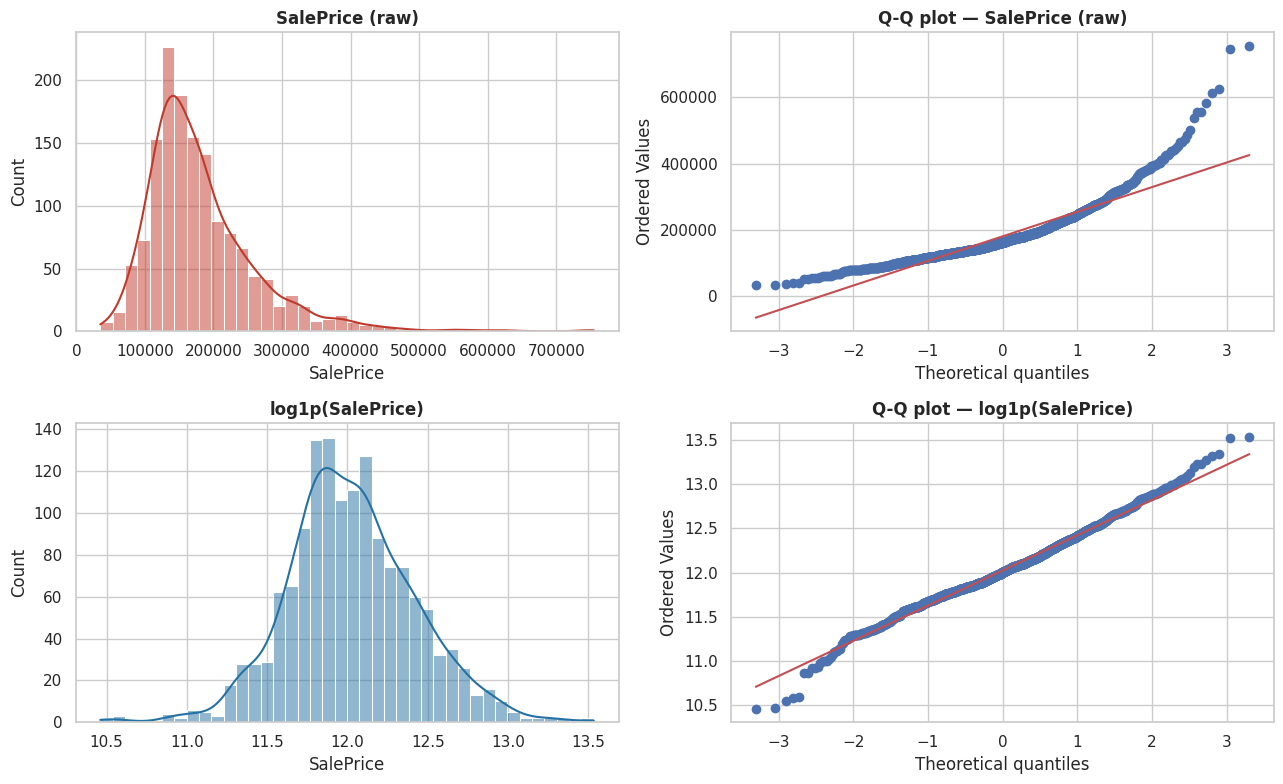

,skewness,excess kurtosis,Shapiro-Wilk p
SalePrice,1.8809,6.5098,0.0
log1p(SalePrice),0.1212,0.8026,0.0


In [4]:
y_raw = raw["SalePrice"]
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
sns.histplot(y_raw, kde=True, bins=40, color="#c0392b", ax=ax[0, 0]); ax[0, 0].set_title("SalePrice (raw)")
stats.probplot(y_raw, dist="norm", plot=ax[0, 1]); ax[0, 1].set_title("Q-Q plot — SalePrice (raw)")
sns.histplot(np.log1p(y_raw), kde=True, bins=40, color="#2471a3", ax=ax[1, 0]); ax[1, 0].set_title("log1p(SalePrice)")
stats.probplot(np.log1p(y_raw), dist="norm", plot=ax[1, 1]); ax[1, 1].set_title("Q-Q plot — log1p(SalePrice)")
plt.tight_layout(); savefig("01_target_distribution"); plt.show()

sk_raw, sk_log = stats.skew(y_raw), stats.skew(np.log1p(y_raw))
ku_raw, ku_log = stats.kurtosis(y_raw), stats.kurtosis(np.log1p(y_raw))
sh_raw = stats.shapiro(y_raw).pvalue; sh_log = stats.shapiro(np.log1p(y_raw)).pvalue
display(pd.DataFrame({"skewness": [sk_raw, sk_log], "excess kurtosis": [ku_raw, ku_log],
                      "Shapiro-Wilk p": [sh_raw, sh_log]}, index=["SalePrice", "log1p(SalePrice)"]).round(4))

**Is `SalePrice` normally distributed? No.** The histogram is **right-skewed** with a long tail of expensive homes; the Q-Q plot bends sharply upward away from the red line at the right end, and the Shapiro–Wilk test rejects normality (p ≈ 0). Skewness is **≈ 1.88** (a normal curve has 0) with heavy tails (excess kurtosis ≈ 6.5).

Applying **`log1p`** compresses the tail: skewness falls to **≈ 0.12**, the histogram becomes close to bell-shaped and the Q-Q points follow the line except for a few very cheap homes. A (near-)normal target is what linear models assume of their errors, and on a log scale errors become *percentage* errors — the natural way to think about house prices. We therefore model `log1p(SalePrice)` and convert predictions back with `expm1`.

### 2.2 Univariate analysis

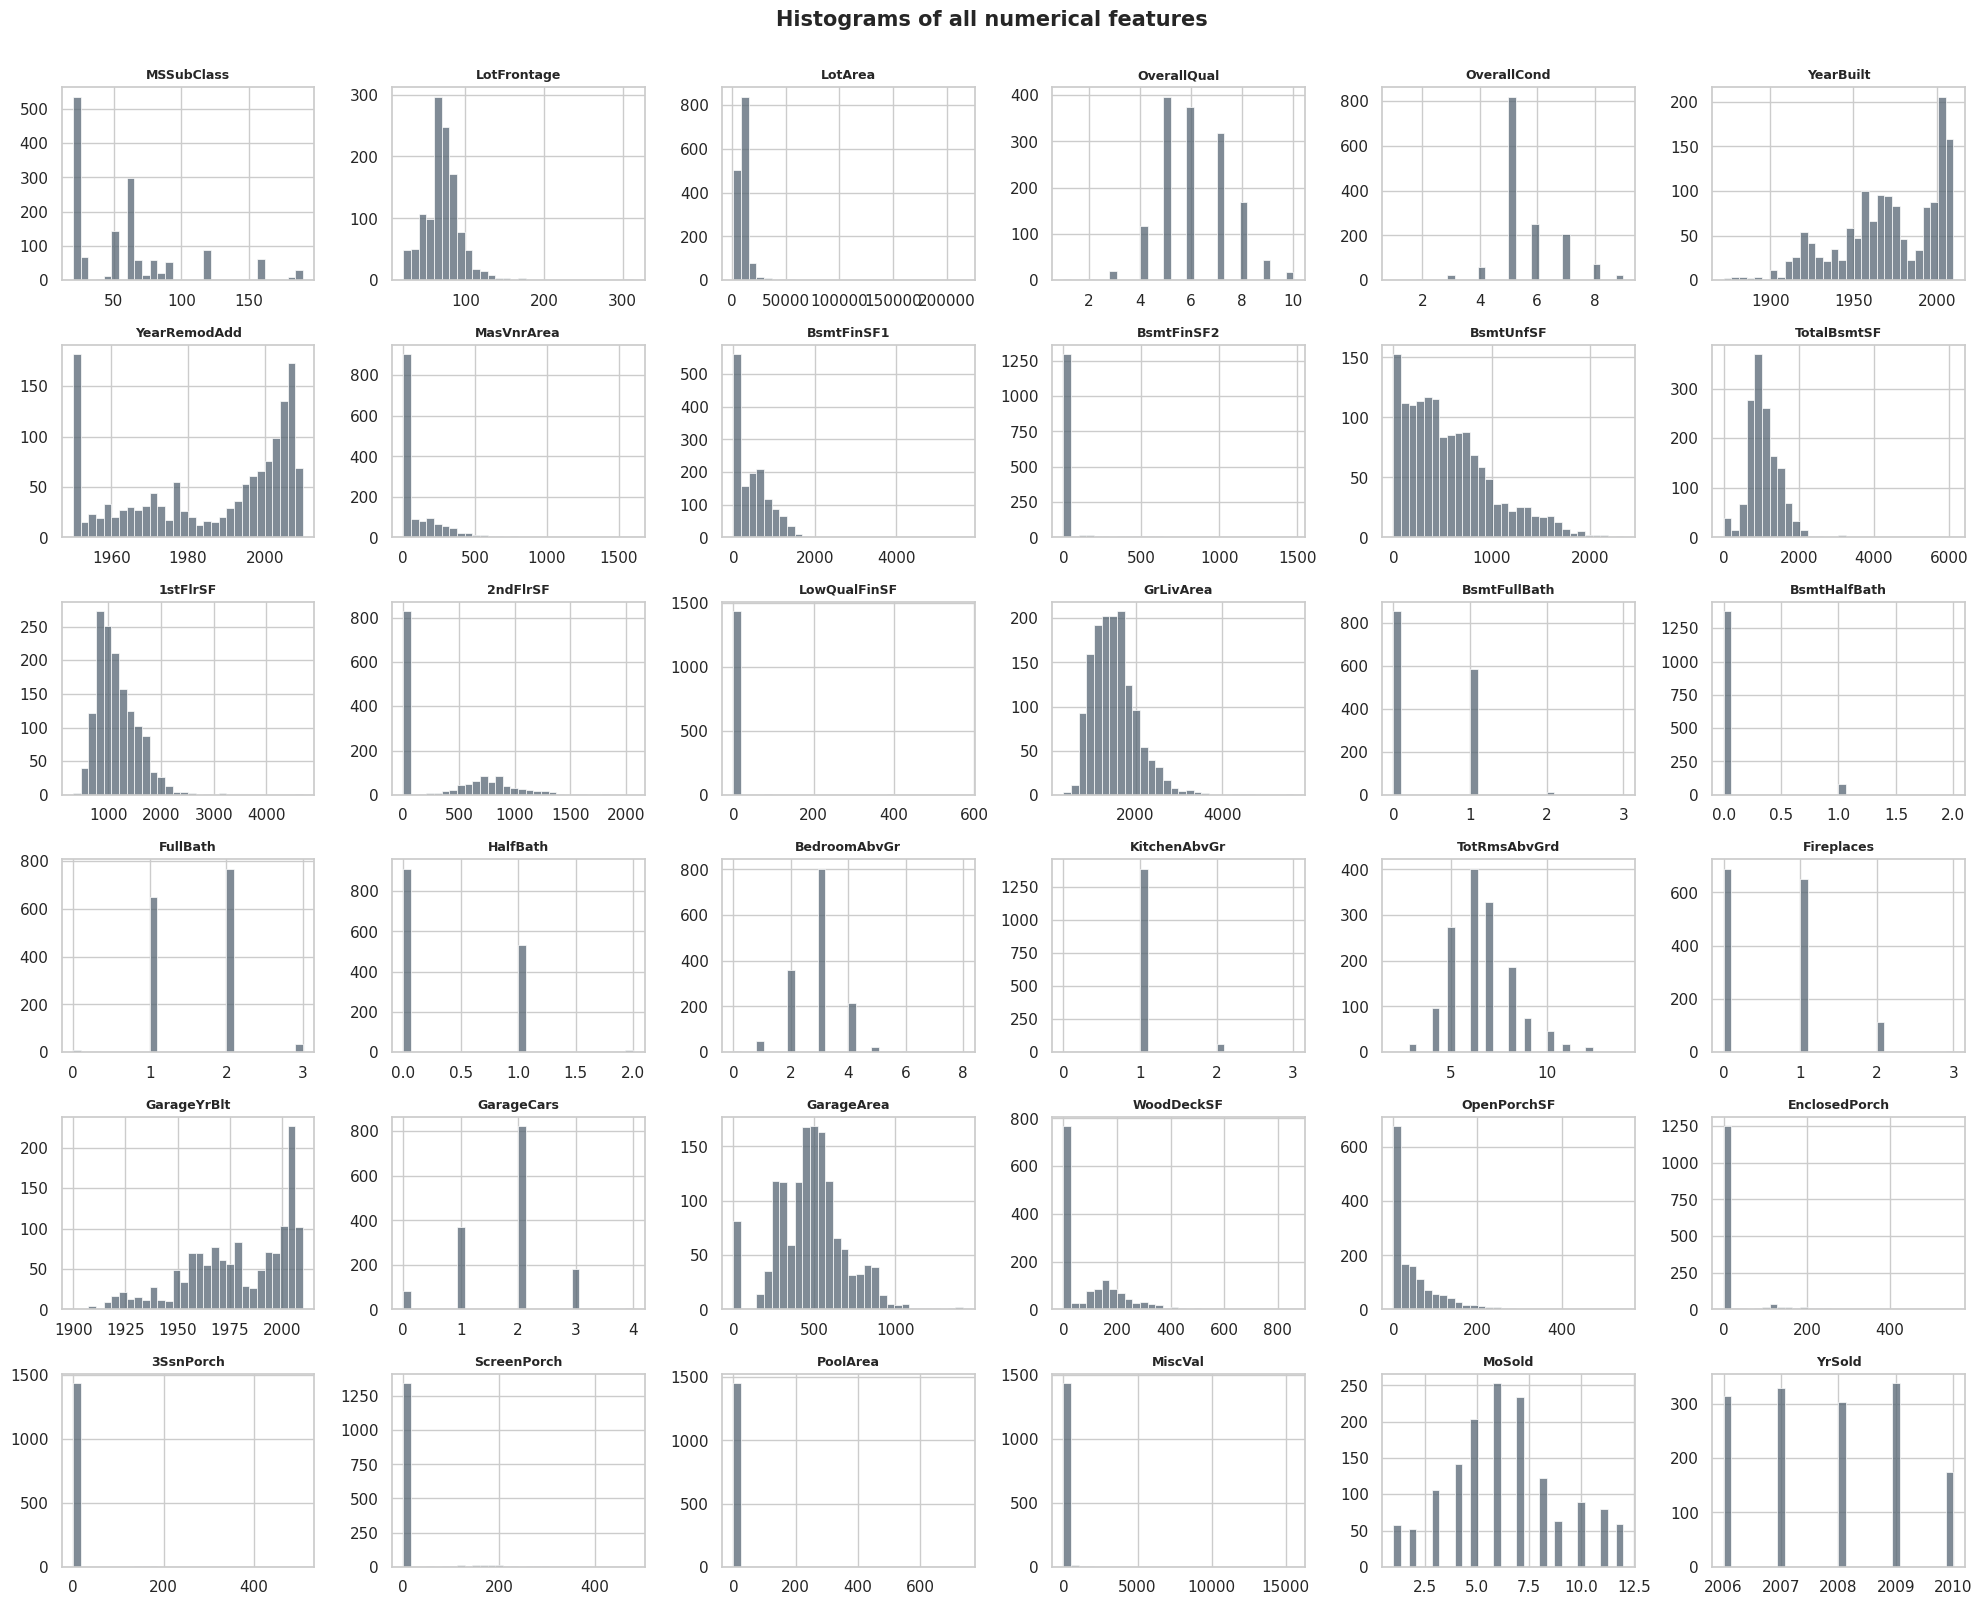

In [5]:
num_feats = raw[num_cols_all]
fig, axes = plt.subplots(6, 6, figsize=(20, 16))
for a, c in zip(axes.ravel(), num_cols_all):
    sns.histplot(raw[c], bins=30, color="#566573", ax=a); a.set_title(c, fontsize=9); a.set_xlabel(""); a.set_ylabel("")
for a in axes.ravel()[len(num_cols_all):]: a.axis("off")
plt.suptitle("Histograms of all numerical features", y=1.002, fontsize=15, fontweight="bold")
plt.tight_layout(); savefig("02_numeric_histograms"); plt.show()

,skewness
MiscVal,24.48
PoolArea,14.83
LotArea,12.21
3SsnPorch,10.30
LowQualFinSF,9.01


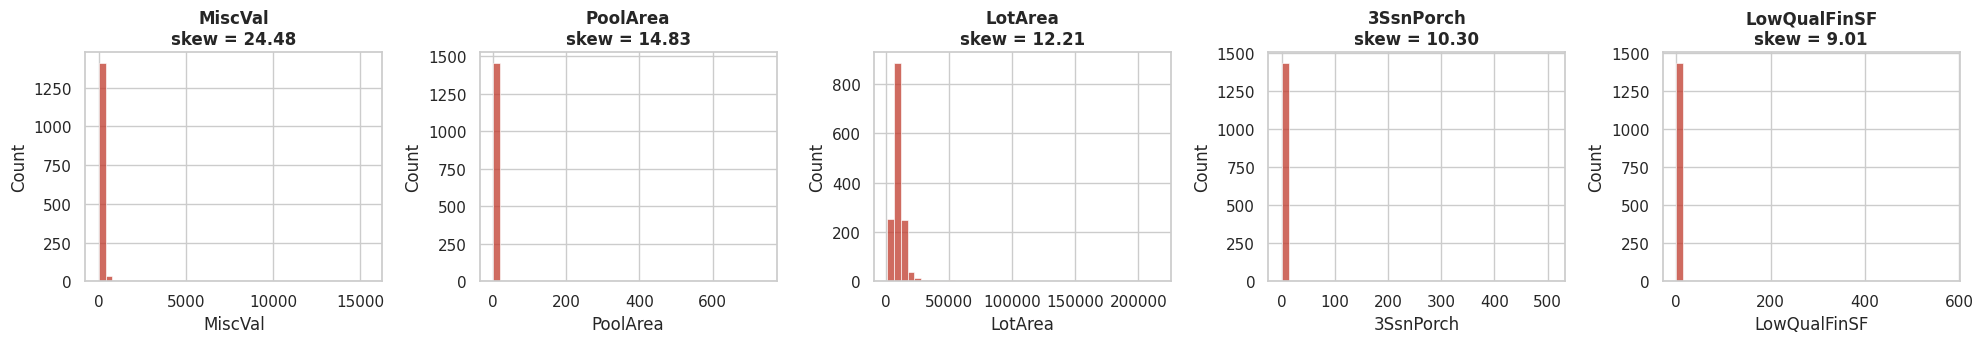

Features with |skew| > 0.75: 21 of 36


In [6]:
skew_all = num_feats.skew().sort_values(ascending=False)
top5_skew = skew_all.head(5)
display(top5_skew.rename("skewness").to_frame().round(2))
fig, axes = plt.subplots(1, 5, figsize=(20, 3.6))
for a, c in zip(axes, top5_skew.index):
    sns.histplot(raw[c], bins=40, color="#c0392b", ax=a); a.set_title(f"{c}\nskew = {top5_skew[c]:.2f}")
plt.tight_layout(); savefig("03_top5_skewed"); plt.show()
print("Features with |skew| > 0.75:", int((skew_all.abs() > 0.75).sum()), "of", len(skew_all))

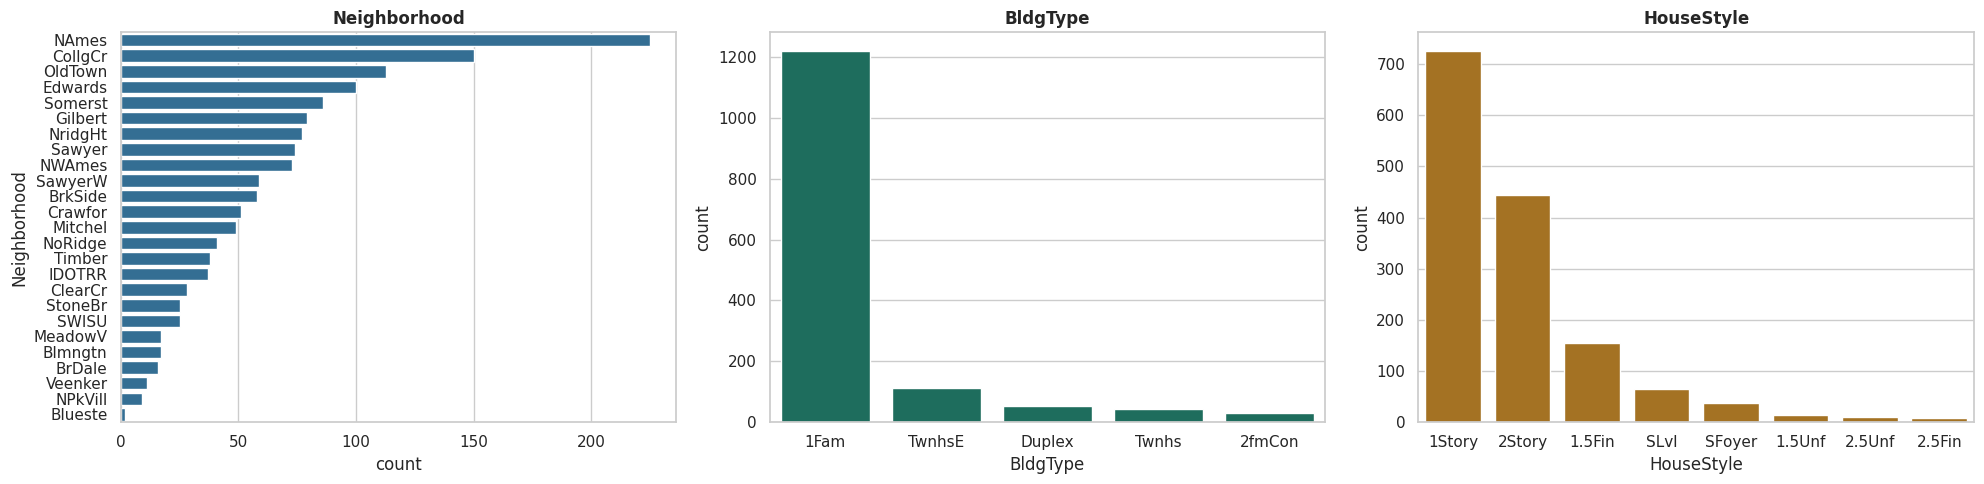

Most frequent: Neighborhood = NAmes | BldgType = 1Fam (84%) | HouseStyle = 1Story (50%)


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
order_n = raw["Neighborhood"].value_counts().index
sns.countplot(data=raw, y="Neighborhood", order=order_n, color="#2471a3", ax=axes[0]); axes[0].set_title("Neighborhood")
sns.countplot(data=raw, x="BldgType", order=raw["BldgType"].value_counts().index, color="#117a65", ax=axes[1]); axes[1].set_title("BldgType")
sns.countplot(data=raw, x="HouseStyle", order=raw["HouseStyle"].value_counts().index, color="#b9770e", ax=axes[2]); axes[2].set_title("HouseStyle")
plt.tight_layout(); savefig("04_countplots"); plt.show()
print("Most frequent: Neighborhood =", raw.Neighborhood.mode()[0], "| BldgType =", raw.BldgType.mode()[0],
      f"({(raw.BldgType == raw.BldgType.mode()[0]).mean():.0%})", "| HouseStyle =", raw.HouseStyle.mode()[0],
      f"({(raw.HouseStyle == raw.HouseStyle.mode()[0]).mean():.0%})")

### 2.3 Bivariate analysis

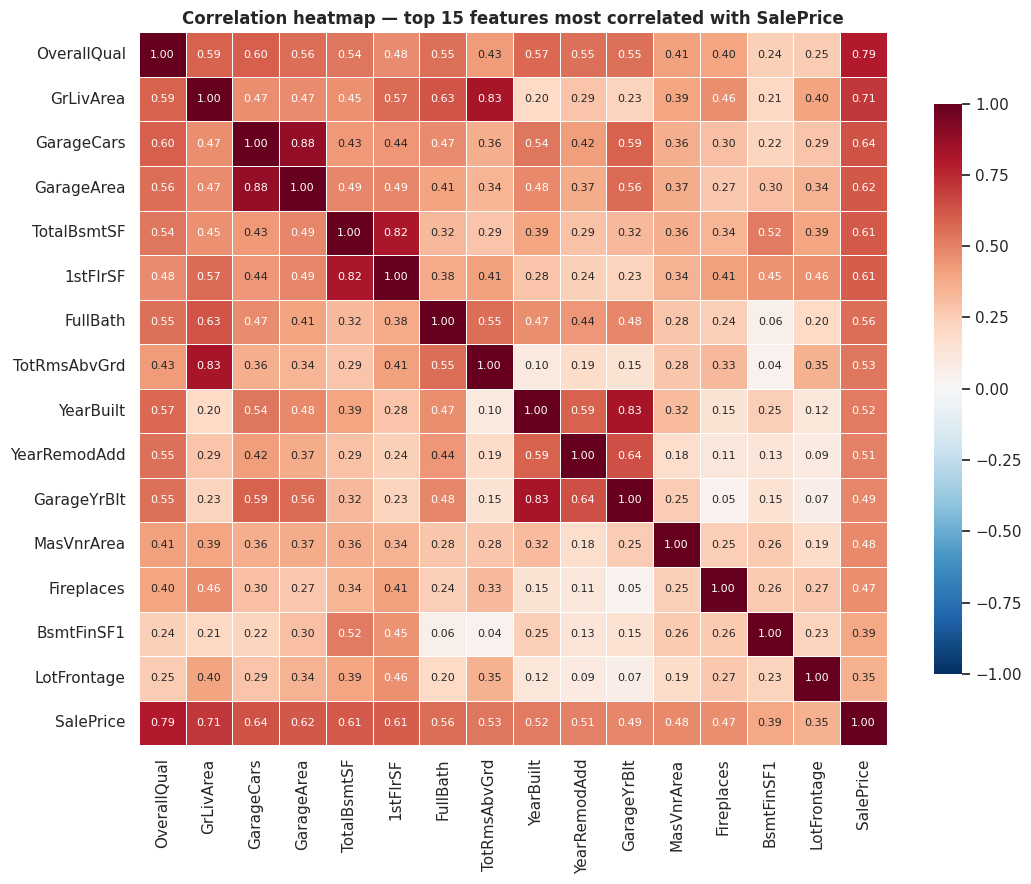

,OverallQual,GrLivArea,GarageCars,GarageArea,TotalBsmtSF,1stFlrSF,FullBath,TotRmsAbvGrd,YearBuilt,YearRemodAdd,GarageYrBlt,MasVnrArea,Fireplaces,BsmtFinSF1,LotFrontage
corr with SalePrice,0.791,0.709,0.64,0.623,0.614,0.606,0.561,0.534,0.523,0.507,0.486,0.477,0.467,0.386,0.352


In [8]:
corr_target = raw[num_cols_all + ["SalePrice"]].corr()["SalePrice"].drop("SalePrice")
top15 = corr_target.abs().sort_values(ascending=False).head(15).index.tolist()
plt.figure(figsize=(11, 9))
sns.heatmap(raw[top15 + ["SalePrice"]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=.5, cbar_kws={"shrink": .8}, annot_kws={"size": 8})
plt.title("Correlation heatmap — top 15 features most correlated with SalePrice"); plt.tight_layout()
savefig("05_corr_heatmap"); plt.show()
display(corr_target.loc[top15].rename("corr with SalePrice").to_frame().round(3).T)

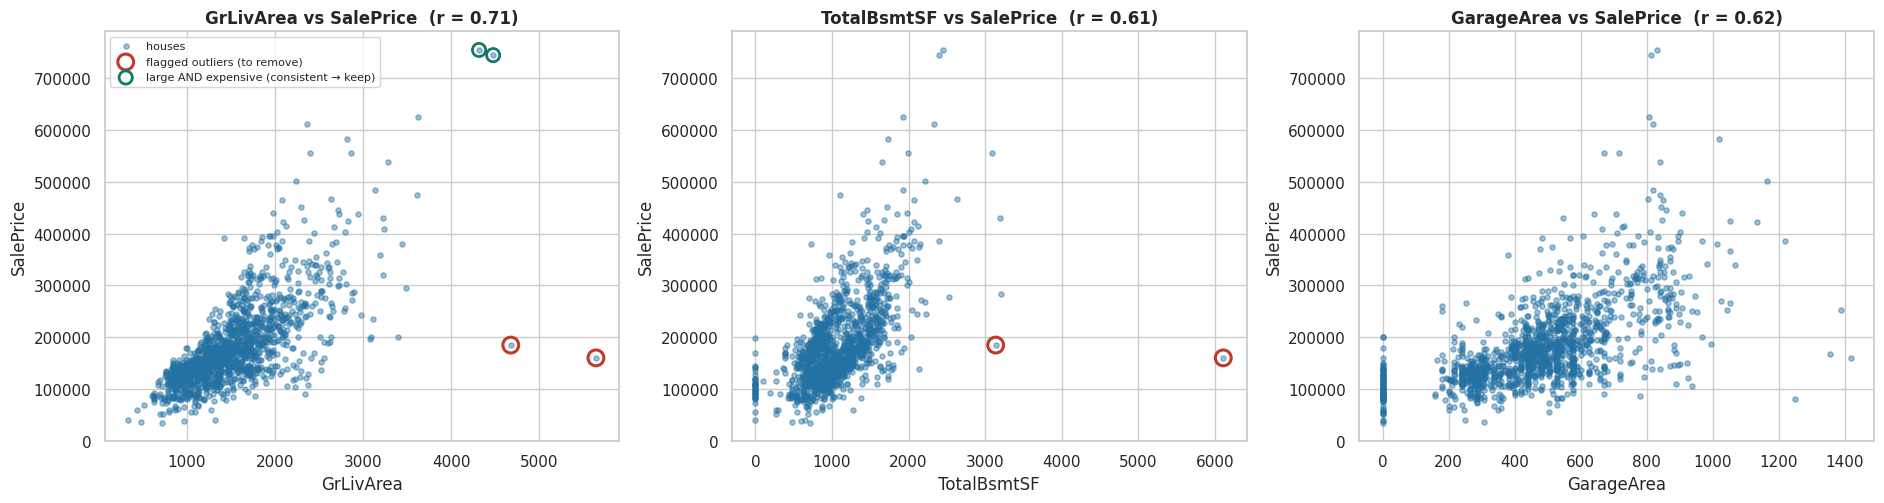

Houses with GrLivArea > 4000:


,Id,GrLivArea,TotalBsmtSF,OverallQual,Neighborhood,SaleCondition,SalePrice
523,524,4676,3138,10,Edwards,Partial,184750
691,692,4316,2444,10,NoRidge,Normal,755000
1182,1183,4476,2396,10,NoRidge,Abnorml,745000
1298,1299,5642,6110,10,Edwards,Partial,160000


IQR rule on GrLivArea (upper fence 2748 sq ft): 31 statistical outliers
→ Flagged as *erroneous / atypical* sales (huge area, tiny price): [523, 1298] (row index)


In [9]:
out_mask_raw = (raw["GrLivArea"] > 4000) & (raw["SalePrice"] < 300000)      # the 2 extreme points
big_all = raw["GrLivArea"] > 4000
fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
for a, c in zip(axes, ["GrLivArea", "TotalBsmtSF", "GarageArea"]):
    a.scatter(raw[c], raw["SalePrice"], s=14, alpha=.45, color="#2471a3", label="houses")
    a.set_xlabel(c); a.set_ylabel("SalePrice"); a.set_title(f"{c} vs SalePrice  (r = {raw[c].corr(raw.SalePrice):.2f})")
axes[0].scatter(raw.loc[out_mask_raw, "GrLivArea"], raw.loc[out_mask_raw, "SalePrice"], s=130, facecolors="none",
                edgecolors="#c0392b", linewidths=2.2, label="flagged outliers (to remove)")
axes[0].scatter(raw.loc[big_all & ~out_mask_raw, "GrLivArea"], raw.loc[big_all & ~out_mask_raw, "SalePrice"], s=90,
                facecolors="none", edgecolors="#117a65", linewidths=2, label="large AND expensive (consistent → keep)")
axes[1].scatter(raw.loc[out_mask_raw, "TotalBsmtSF"], raw.loc[out_mask_raw, "SalePrice"], s=130, facecolors="none", edgecolors="#c0392b", linewidths=2.2)
axes[0].legend(loc="upper left", fontsize=8)
plt.tight_layout(); savefig("06_scatter_key_features"); plt.show()

print("Houses with GrLivArea > 4000:")
display(raw.loc[big_all, ["Id", "GrLivArea", "TotalBsmtSF", "OverallQual", "Neighborhood", "SaleCondition", "SalePrice"]])
q1, q3 = raw.GrLivArea.quantile([.25, .75]); iqr = q3 - q1
print(f"IQR rule on GrLivArea (upper fence {q3 + 1.5 * iqr:.0f} sq ft): {(raw.GrLivArea > q3 + 1.5 * iqr).sum()} statistical outliers")
print("→ Flagged as *erroneous / atypical* sales (huge area, tiny price):", raw.index[out_mask_raw].tolist(), "(row index)")

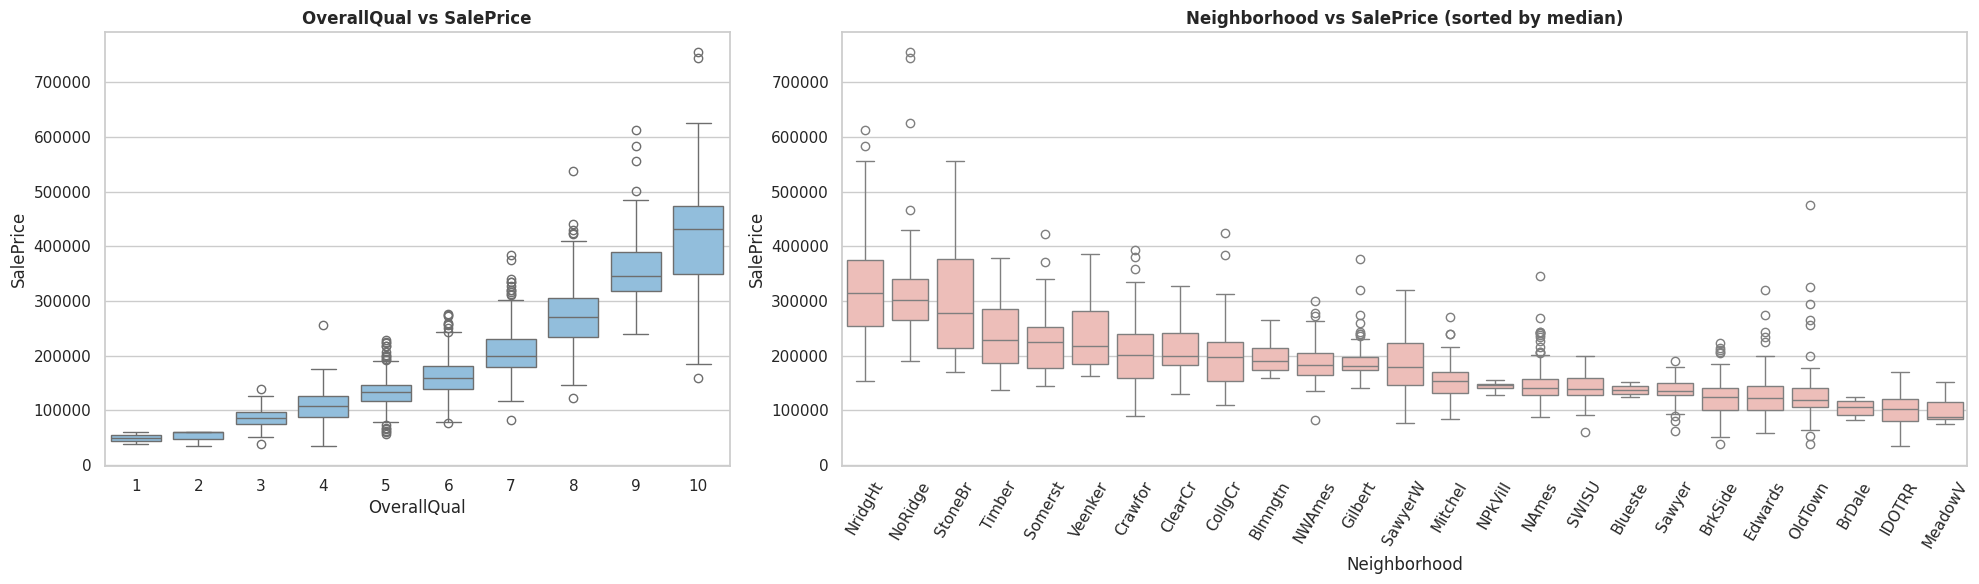

Priciest neighborhoods by MEDIAN price:


Neighborhood,NridgHt,NoRidge,StoneBr
median SalePrice,315000,301500,278000


Cheapest: MeadowV (median $88,000)
Median price rises from $86,250 (OverallQual 3) to $432,390 (OverallQual 10).


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(20, 6), gridspec_kw={"width_ratios": [1, 1.8]})
sns.boxplot(data=raw, x="OverallQual", y="SalePrice", color="#85c1e9", ax=axes[0]); axes[0].set_title("OverallQual vs SalePrice")
order_med = raw.groupby("Neighborhood")["SalePrice"].median().sort_values(ascending=False)
sns.boxplot(data=raw, x="Neighborhood", y="SalePrice", order=order_med.index, color="#f5b7b1", ax=axes[1])
axes[1].tick_params(axis="x", rotation=60); axes[1].set_title("Neighborhood vs SalePrice (sorted by median)")
plt.tight_layout(); savefig("07_boxplots"); plt.show()
print("Priciest neighborhoods by MEDIAN price:")
display(order_med.head(3).rename("median SalePrice").to_frame().astype(int).T)
print("Cheapest:", order_med.tail(1).index[0], f"(median ${order_med.iloc[-1]:,.0f})")
print(f"Median price rises from ${raw[raw.OverallQual==3].SalePrice.median():,.0f} (OverallQual 3) to "
      f"${raw[raw.OverallQual==10].SalePrice.median():,.0f} (OverallQual 10).")

---
## Step 3 — Data Preprocessing & Feature Engineering
### 3.1 Handle missing values
Rules from the exam sheet, applied with `house_preprocessing.handle_missing()`:
- report every column with missing values and its %;
- **categorical** NaN that means *absent* → `'None'` (e.g. `GarageType`, `BsmtQual`, `FireplaceQu`);
- **numeric** NaN that means *absent* → `0` (e.g. `GarageArea`, `BsmtFinSF1`, `MasVnrArea`);
- drop columns with **> 80 % missing**, measured on the raw data (`PoolQC`, `MiscFeature`, `Alley`, `Fence` — almost entirely "feature absent", so they carry very little information);
- the **remaining** numeric NaN (`LotFrontage`, `GarageYrBlt`) → **median** and the single `Electrical` NaN → most-frequent. These two are imputed **inside the Pipeline** so the fill value is learned from training rows only (no leakage).

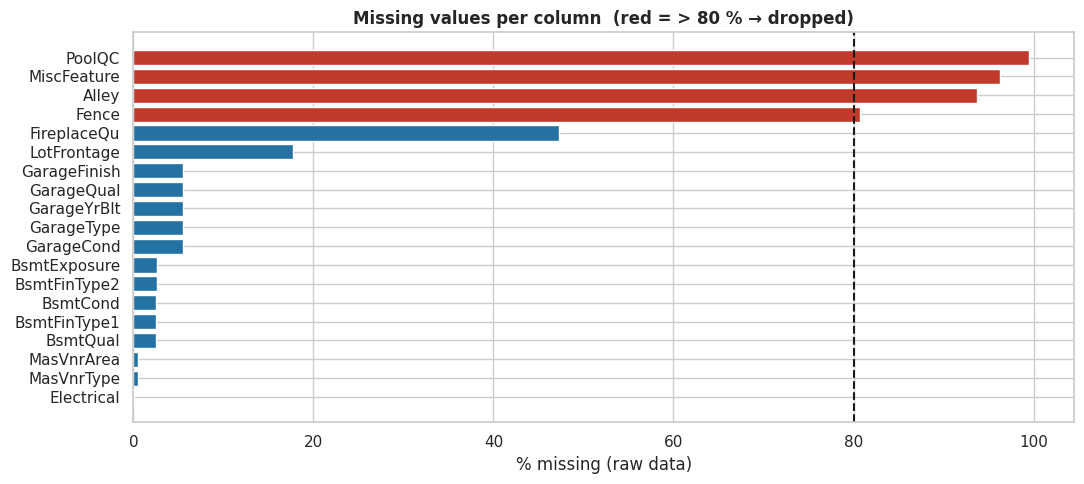

Columns dropped (> 80 % missing): ['Alley', 'Fence', 'MiscFeature', 'PoolQC']

Missing values left AFTER the rule-based fills (handled inside the Pipeline):


,missing
LotFrontage,259
Electrical,1
GarageYrBlt,81


Shape after handling missing values: (1460, 77)


In [11]:
miss_pct = (raw.isna().mean() * 100).sort_values(ascending=False)
miss_pct = miss_pct[miss_pct > 0]
plt.figure(figsize=(11, 5))
colors = ["#c0392b" if v > 80 else "#2471a3" for v in miss_pct.values]
plt.barh(miss_pct.index[::-1], miss_pct.values[::-1], color=colors[::-1]); plt.axvline(80, ls="--", color="k")
plt.xlabel("% missing (raw data)"); plt.title("Missing values per column  (red = > 80 % → dropped)")
plt.tight_layout(); savefig("08_missing_values"); plt.show()

sparse_cols = find_sparse_columns(raw, 0.80)
print("Columns dropped (> 80 % missing):", sparse_cols)
df_clean = handle_missing(raw, drop_cols=sparse_cols)
left = df_clean.isna().sum(); left = left[left > 0]
print("\nMissing values left AFTER the rule-based fills (handled inside the Pipeline):")
display(left.to_frame("missing"))
print("Shape after handling missing values:", df_clean.shape)

### 3.2 Outlier removal
Remove the 2 rows with `GrLivArea > 4000` **and** `SalePrice < 300000`.

In [12]:
out_mask = (df_clean["GrLivArea"] > 4000) & (df_clean["SalePrice"] < 300000)
print("Rows removed:", df_clean.index[out_mask].tolist())

def ols_gla(frame):
    m = LinearRegression().fit(frame[["GrLivArea"]], frame["SalePrice"])
    return m.coef_[0], m.intercept_, m.score(frame[["GrLivArea"]], frame["SalePrice"])
b_with = ols_gla(df_clean); b_wo = ols_gla(df_clean[~out_mask])
display(pd.DataFrame({"slope ($ per sq ft)": [b_with[0], b_wo[0]], "intercept": [b_with[1], b_wo[1]],
                      "R² (GrLivArea only)": [b_with[2], b_wo[2]]},
                     index=["with the 2 outliers", "without"]).round(3))

df_clean = df_clean[~out_mask].copy()
raw_model = raw[~out_mask].copy()                  # same rows, untouched raw values (used for the final end-to-end pipeline)
print("Shape after outlier removal:", df_clean.shape)

Rows removed: [523, 1298]


,slope ($ per sq ft),intercept,R² (GrLivArea only)
with the 2 outliers,107.13,18569.026,0.502
without,115.04,7168.970,0.540


Shape after outlier removal: (1458, 77)


**Why remove them?** Houses #524 and #1299 are the largest in the data (4,676 and 5,642 sq ft, top quality 10) yet sold for only **$184,750** and **$160,000**; both are `SaleCondition = Partial` (sold before completion), so the price does not reflect the finished house — the dataset's author recommends removing exactly such sales. Because they sit far from the other points on the x-axis (**high leverage**) *and* far below the trend (**large residual**), a linear model bends towards them: the table above shows the fitted slope drops from **$115 to $107 per sq ft** and R² from 0.540 to 0.502 for the simple fit, and Ridge/Lasso would inherit the same distortion for *every* house. The two other >4,000 sq ft homes ($755k and $745k) follow the trend, so they are kept.

### 3.3 Feature engineering
`TotalSF = TotalBsmtSF + 1stFlrSF + 2ndFlrSF` · `HouseAge = YrSold − YearBuilt` · `RemodAge = YrSold − YearRemodAdd` · `HasGarage` · `HasPool`.

In [13]:
neg_house = int((raw_model.YrSold - raw_model.YearBuilt < 0).sum()); neg_remod = int((raw_model.YrSold - raw_model.YearRemodAdd < 0).sum())
print(f"Rows where the formula gives a negative age (sold before build / remodel year) in this data: HouseAge={neg_house}, RemodAge={neg_remod}  (a clip at 0 is kept as a safety net for unseen data)")
df_clean = engineer_features(df_clean)
display(df_clean[["TotalBsmtSF", "1stFlrSF", "2ndFlrSF", "TotalSF", "YrSold", "YearBuilt", "HouseAge", "RemodAge",
                  "GarageArea", "HasGarage", "PoolArea", "HasPool"]].head())
print("HasGarage = 1 for", df_clean.HasGarage.mean().round(3) * 100, "% of houses |  HasPool = 1 for", round(df_clean.HasPool.mean() * 100, 2), "%")
print("corr(TotalSF, SalePrice) =", round(df_clean.TotalSF.corr(df_clean.SalePrice), 3),
      "  vs  corr(GrLivArea, SalePrice) =", round(df_clean.GrLivArea.corr(df_clean.SalePrice), 3))

Rows where the formula gives a negative age (sold before build / remodel year) in this data: HouseAge=0, RemodAge=0  (a clip at 0 is kept as a safety net for unseen data)


,TotalBsmtSF,1stFlrSF,2ndFlrSF,TotalSF,YrSold,YearBuilt,HouseAge,RemodAge,GarageArea,HasGarage,PoolArea,HasPool
0,856,856,854,2566,2008,2003,5,5,548,1,0,0
1,1262,1262,0,2524,2007,1976,31,31,460,1,0,0
2,920,920,866,2706,2008,2001,7,6,608,1,0,0
3,756,961,756,2473,2006,1915,91,36,642,1,0,0
4,1145,1145,1053,3343,2008,2000,8,8,836,1,0,0


HasGarage = 1 for 94.39999999999999 % of houses |  HasPool = 1 for 0.41 %
corr(TotalSF, SalePrice) = 0.833   vs  corr(GrLivArea, SalePrice) = 0.735


### 3.4 Encoding & scaling
| Block | Columns | Treatment |
|---|---|---|
| **Ordinal quality** | `ExterQual, KitchenQual, BsmtQual, FireplaceQu` **+** `ExterCond, BsmtCond, HeatingQC, GarageQual, GarageCond` (same Po→Ex scale) | `Po→1, Fa→2, TA→3, Gd→4, Ex→5, None→0` (applied now — deterministic) |
| **Skewed continuous** (skew > 0.75, measured on *train*) | area / size / age columns | median-impute → `log1p` → `StandardScaler` |
| **Other numeric** (incl. ordinal codes, counts, years, flags) | | median-impute → `StandardScaler` |
| **Nominal, ≤ 10 categories** | `BldgType, HouseStyle, SaleCondition, …` | most-frequent impute → One-Hot (`handle_unknown="ignore"`) |
| **Nominal, > 10 categories** | `Neighborhood, Exterior1st, Exterior2nd, MSSubClass` | **mean-target encoding** (`TargetEncoder`, internally cross-fitted + smoothed → no target leakage) → `StandardScaler` |

`MSSubClass` is a *code* for the dwelling type, not a quantity, so it is treated as nominal. Everything above is wrapped in one `ColumnTransformer` + `Pipeline`.

In [14]:
df_clean = encode_ordinal(df_clean)
display(df_clean[ORDINAL_COLS].head(3))
print("Any NaN left in ordinal columns?", int(df_clean[ORDINAL_COLS].isna().sum().sum()))

,ExterQual,ExterCond,BsmtQual,BsmtCond,HeatingQC,KitchenQual,FireplaceQu,GarageQual,GarageCond
0,4,3,4,3,5,4,0,3,3
1,3,3,4,3,5,3,3,3,3
2,4,3,4,3,5,4,3,3,3


Any NaN left in ordinal columns? 0


### 3.5 Target transform & train–test split
`y = log1p(SalePrice)` is created **before** splitting; split 80 / 20 with `random_state=42`. The pre-processor is then fitted on the training rows only (next cell).

In [15]:
y_log = np.log1p(df_clean["SalePrice"])
X_clean = df_clean.drop(columns=["SalePrice", "Id"])
X_train, X_test, y_train, y_test = train_test_split(X_clean, y_log, test_size=0.20, random_state=RANDOM_STATE)
X_train_raw = raw_model.loc[X_train.index].drop(columns=["SalePrice"])      # identical rows, un-processed (for the final pipeline)
X_test_raw  = raw_model.loc[X_test.index].drop(columns=["SalePrice"])
print("X_train:", X_train.shape, "| X_test:", X_test.shape, "| y_train:", y_train.shape, "| y_test:", y_test.shape)
assert (X_train_raw.index == X_train.index).all() and (X_test_raw.index == X_test.index).all()

# sanity: the sklearn HouseCleaner (used in the final pipeline) reproduces the step-by-step cleaning exactly
check = HouseCleaner().fit(raw_model.drop(columns="SalePrice")).transform(raw_model.drop(columns="SalePrice"))
assert check.shape == X_clean.shape and check.equals(X_clean.loc[check.index][check.columns]), "cleaner mismatch!"
print("✔ HouseCleaner(raw) == step-by-step cleaning")

X_train: (1166, 80) | X_test: (292, 80) | y_train: (1166,) | y_test: (292,)
✔ HouseCleaner(raw) == step-by-step cleaning


In [16]:
# ---- build the ColumnTransformer (column groups are decided from TRAINING data only) ----
CONTINUOUS = ["LotFrontage", "LotArea", "MasVnrArea", "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF",
              "1stFlrSF", "2ndFlrSF", "LowQualFinSF", "GrLivArea", "GarageArea", "WoodDeckSF", "OpenPorchSF",
              "EnclosedPorch", "3SsnPorch", "ScreenPorch", "PoolArea", "MiscVal", "TotalSF", "HouseAge", "RemodAge"]
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()
num_cols = [c for c in X_train.columns if c not in cat_cols]
skew_tr = X_train[CONTINUOUS].skew()
skewed_cols = skew_tr[skew_tr > 0.75].index.tolist()
other_num = [c for c in num_cols if c not in skewed_cols]
card = X_train[cat_cols].nunique()
low_card = card[card <= 10].index.tolist(); high_card = card[card > 10].index.tolist()

print(f"numeric: {len(num_cols)}  (skewed→log1p: {len(skewed_cols)}, other: {len(other_num)}) | categorical: {len(cat_cols)} "
      f"(one-hot: {len(low_card)}, target-encoded: {len(high_card)})")
display(skew_tr.sort_values(ascending=False).round(2).to_frame("train skew").T)
print("High-cardinality columns → mean-target encoding:", card[high_card].to_dict())

def make_preprocessor():
    return ColumnTransformer([
        ("skewed", Pipeline([("imp", SimpleImputer(strategy="median")),
                             ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                             ("sc", StandardScaler())]), skewed_cols),
        ("numeric", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), other_num),
        ("onehot", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                             ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), low_card),
        ("target", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                             ("te", TargetEncoder(target_type="continuous", smooth="auto", cv=5, random_state=RANDOM_STATE)),
                             ("sc", StandardScaler())]), high_card),
    ], verbose_feature_names_out=False)

# fit_transform (not fit + transform): TargetEncoder only cross-fits its encodings inside fit_transform, so the
# model never sees encodings computed from a row's own target. Fitted on TRAIN only; the test set is only transformed.
preprocessor = make_preprocessor()
A_train = preprocessor.fit_transform(X_train, y_train); A_test = preprocessor.transform(X_test)
feat_names = preprocessor.get_feature_names_out()
print("\nProcessed matrices:", A_train.shape, A_test.shape, "| NaN left:", int(np.isnan(A_train).sum() + np.isnan(A_test).sum()))

numeric: 49  (skewed→log1p: 18, other: 31) | categorical: 31 (one-hot: 27, target-encoded: 4)


,MiscVal,PoolArea,LotArea,LowQualFinSF,3SsnPorch,ScreenPorch,BsmtFinSF2,EnclosedPorch,MasVnrArea,OpenPorchSF,LotFrontage,WoodDeckSF,GrLivArea,BsmtUnfSF,TotalSF,1stFlrSF,2ndFlrSF,BsmtFinSF1,HouseAge,RemodAge,TotalBsmtSF,GarageArea
train skew,22.42,15.69,12.3,9.96,9.73,4.09,4.04,3.15,2.45,2.41,1.76,1.55,1.08,0.96,0.89,0.89,0.84,0.76,0.61,0.5,0.45,0.16


High-cardinality columns → mean-target encoding: {'MSSubClass': 15, 'Neighborhood': 25, 'Exterior1st': 15, 'Exterior2nd': 16}



Processed matrices: (1166, 196) (292, 196) | NaN left: 0


---
## Step 4 — Regression Models: Linear, Ridge & Lasso
> **All metrics below are computed after `np.expm1()`** (original USD units). `LogRMSE` (RMSE on log1p scale, the Kaggle leaderboard metric) is shown only as an extra.

In [17]:
y_test_usd = np.expm1(y_test.values)
results, preds, fit_time = {}, {}, {}

def evaluate(name, p_log, secs):
    yp = np.expm1(p_log)
    rmse = mean_squared_error(y_test_usd, yp) ** 0.5
    results[name] = {"RMSE": rmse, "MAE": mean_absolute_error(y_test_usd, yp), "R2": r2_score(y_test_usd, yp),
                     "LogRMSE": mean_squared_error(y_test.values, p_log) ** 0.5,
                     "MAPE %": np.mean(np.abs(yp - y_test_usd) / y_test_usd) * 100,
                     "Within ±10 %": np.mean(np.abs(yp - y_test_usd) / y_test_usd <= 0.10) * 100,
                     "Train time (s)": secs}
    preds[name] = yp
    r = results[name]
    print(f"{name:<20} RMSE = ${r['RMSE']:>9,.0f} | MAE = ${r['MAE']:>9,.0f} | R² = {r['R2']:.4f} | LogRMSE = {r['LogRMSE']:.4f}")

def fit_eval(name, model):
    t = time.time(); model.fit(A_train, y_train.values); secs = time.time() - t
    evaluate(name, model.predict(A_test), secs); return model

def plot_avp(name, ax=None, color="#2471a3", annotate=True):
    ax = ax or plt.gca(); yp = preds[name]; r = results[name]
    ax.scatter(y_test_usd, yp, s=22, alpha=.6, color=color)
    lim = [min(y_test_usd.min(), yp.min()) * .9, max(y_test_usd.max(), yp.max()) * 1.05]
    ax.plot(lim, lim, "k--", lw=1.4, label="perfect model (y = x)"); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel("Actual SalePrice (USD)"); ax.set_ylabel("Predicted SalePrice (USD)"); ax.set_title(f"Actual vs Predicted — {name}"); ax.legend(loc="upper left")
    if annotate:
        ax.text(.97, .05, f"RMSE = ${r['RMSE']:,.0f}\nMAE  = ${r['MAE']:,.0f}\nR²   = {r['R2']:.3f}", transform=ax.transAxes,
                ha="right", va="bottom", bbox=dict(boxstyle="round", fc="white", ec="grey"))

### 4.1 Linear Regression (baseline)

Linear Regression    RMSE = $   22,104 | MAE = $   15,350 | R² = 0.9115 | LogRMSE = 0.1240


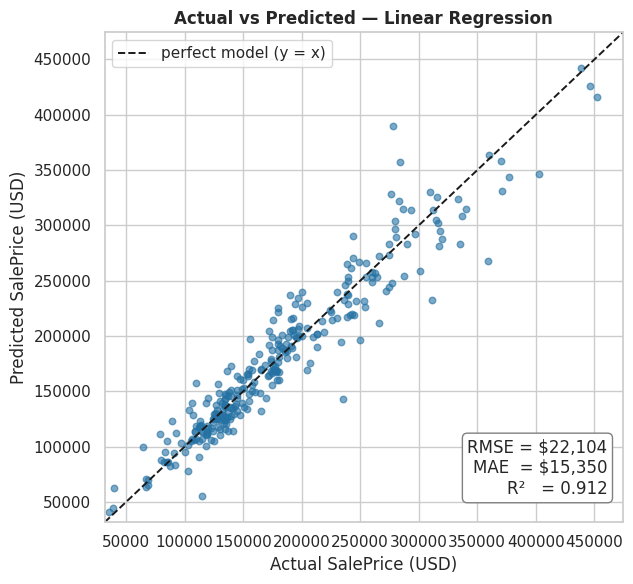

In [18]:
lin = fit_eval("Linear Regression", LinearRegression())
plt.figure(figsize=(6.5, 6)); plot_avp("Linear Regression"); plt.tight_layout(); savefig("09_linear_actual_vs_pred"); plt.show()

**How close are we?** Quite close: the points cluster tightly around the dashed *perfect-model* diagonal, and the plain baseline already explains **91 %** of the variance in sale price (R² = 0.912, typical error ≈ 8.8 %, about 70 % of test houses predicted within ±10 % of the true price). The scatter widens at the cheap and expensive ends, where there are few training examples — the cheapest homes are the most over-predicted (see Step 7).

### 4.2 Ridge Regression (L2)

Ridge                RMSE = $   19,763 | MAE = $   14,242 | R² = 0.9293 | LogRMSE = 0.1130
Best alpha selected by RidgeCV: 10.0


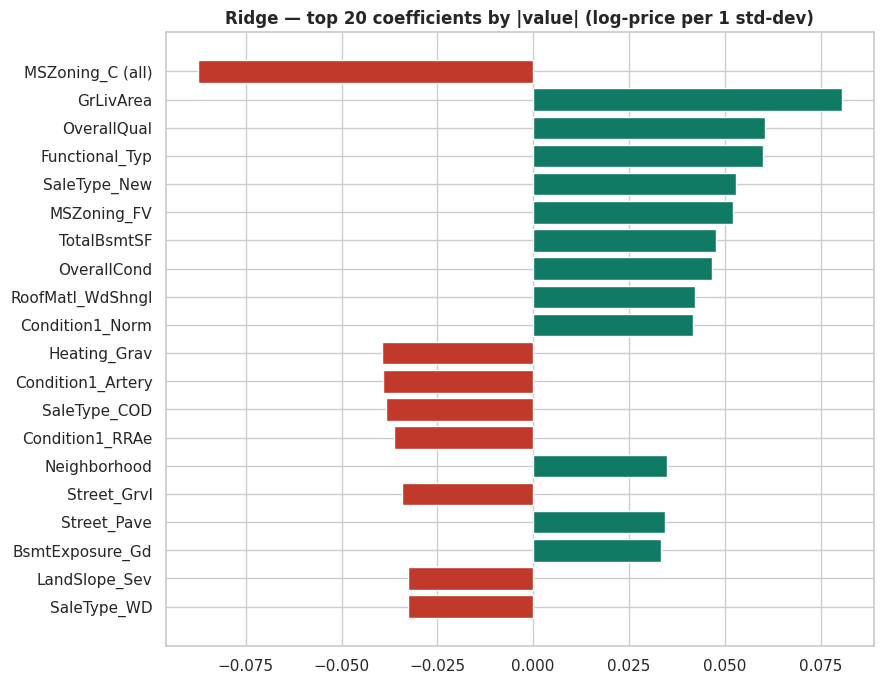

In [19]:
ridge = fit_eval("Ridge", RidgeCV(alphas=[0.01, 0.1, 1, 10, 100]))
print("Best alpha selected by RidgeCV:", ridge.alpha_)
coef_r = pd.Series(ridge.coef_, index=feat_names)
top20 = coef_r.reindex(coef_r.abs().sort_values(ascending=False).head(20).index)[::-1]
plt.figure(figsize=(9, 7)); plt.barh(top20.index, top20.values, color=np.where(top20.values > 0, "#117a65", "#c0392b"))
plt.title("Ridge — top 20 coefficients by |value| (log-price per 1 std-dev)"); plt.tight_layout(); savefig("10_ridge_coefficients"); plt.show()

### 4.3 Lasso Regression (L1)

In [20]:
lasso = fit_eval("Lasso", LassoCV(alphas=[0.0001, 0.001, 0.01, 0.1, 1], max_iter=10000, cv=5, random_state=RANDOM_STATE))
n_zero = int((lasso.coef_ == 0).sum())
print("Best alpha selected by LassoCV:", lasso.alpha_)
print(f"Features zeroed out: {n_zero} of {len(lasso.coef_)}  → {len(lasso.coef_) - n_zero} features kept")
print()
display(pd.DataFrame(results).T[["RMSE", "MAE", "R2", "LogRMSE"]].loc[["Linear Regression", "Ridge", "Lasso"]].round(4))

Lasso                RMSE = $   19,621 | MAE = $   14,271 | R² = 0.9303 | LogRMSE = 0.1142
Best alpha selected by LassoCV: 0.001
Features zeroed out: 129 of 196  → 67 features kept



,RMSE,MAE,R2,LogRMSE
Linear Regression,22104.0567,15349.6282,0.9115,0.1240
Ridge,19762.6003,14241.8099,0.9293,0.1130
Lasso,19620.9694,14271.4093,0.9303,0.1142


**Ridge vs Lasso.** On the hold-out set they are effectively **tied**: Lasso is marginally better in USD RMSE ($19,621 vs $19,763) and R² (0.9303 vs 0.9293), Ridge is marginally better in MAE and log-RMSE (0.1130 vs 0.1142) — all differences are far smaller than the fold-to-fold noise (±$2–3k) seen in cross-validation. Both clearly beat plain OLS ($22,104): with ~196 partly collinear features (`TotalSF`, `GrLivArea`, `1stFlrSF`, one-hot dummies…) OLS coefficients have high variance, and the penalty tames it. **Why they behave differently:** Ridge keeps every feature and shares weight among correlated ones, whereas Lasso (α = 0.001) zeroed **129 of 196** features and matched Ridge's accuracy with only 67 — so Lasso is the better choice if a sparse, easy-to-audit model is needed, Ridge if we want stability among correlated predictors.

---
## Step 5 — Advanced Models: Random Forest & XGBoost
### 5.1 Random Forest

Random Forest        RMSE = $   22,113 | MAE = $   15,486 | R² = 0.9115 | LogRMSE = 0.1372


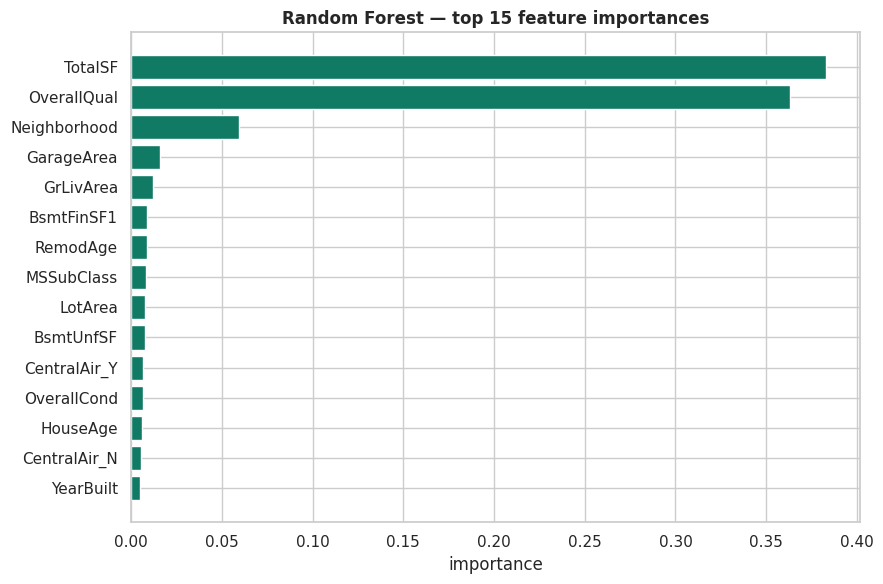

In [21]:
rf = fit_eval("Random Forest", RandomForestRegressor(n_estimators=200, max_depth=10, random_state=RANDOM_STATE, n_jobs=-1))
def plot_importance(model, title, fname, color):
    imp = pd.Series(model.feature_importances_, index=feat_names).sort_values(ascending=False).head(15)[::-1]
    plt.figure(figsize=(9, 6)); plt.barh(imp.index, imp.values, color=color); plt.title(title); plt.xlabel("importance")
    plt.tight_layout(); savefig(fname); plt.show(); return imp[::-1]
rf_imp = plot_importance(rf, "Random Forest — top 15 feature importances", "11_rf_importance", "#117a65")

### 5.2 XGBoost Regressor

XGBoost              RMSE = $   20,410 | MAE = $   14,665 | R² = 0.9246 | LogRMSE = 0.1195


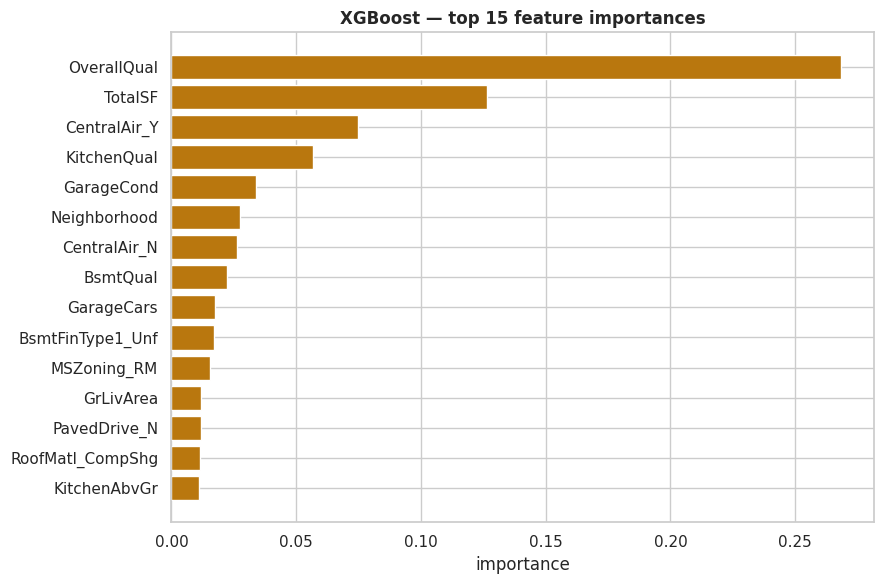

In [22]:
xgb_params = dict(n_estimators=500, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE)
xgb = fit_eval("XGBoost", XGBRegressor(**xgb_params))
xgb_imp = plot_importance(xgb, "XGBoost — top 15 feature importances", "12_xgb_importance", "#b9770e")

### 5.3 Cross-validation
The models were *trained* on 80 % of the data; 5-fold CV on that same training portion gives an honest, leakage-free estimate (the **entire** pre-processing pipeline is re-fitted inside every fold). We compute it for all five models, then discuss the best one.

In [23]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
usd_scorer = make_scorer(lambda yt, yp: mean_squared_error(np.expm1(yt), np.expm1(yp)) ** 0.5, greater_is_better=False)
base_models = {"Linear Regression": LinearRegression(),
               "Ridge": RidgeCV(alphas=[0.01, 0.1, 1, 10, 100]),
               "Lasso": LassoCV(alphas=[0.0001, 0.001, 0.01, 0.1, 1], max_iter=10000, cv=5, random_state=RANDOM_STATE),
               "Random Forest": RandomForestRegressor(n_estimators=200, max_depth=10, random_state=RANDOM_STATE, n_jobs=-1),
               "XGBoost": XGBRegressor(**xgb_params)}
cv_res = {}
def run_cv(name, model):
    pipe = Pipeline([("prep", make_preprocessor()), ("model", clone(model))])
    s = cross_validate(pipe, X_train, y_train, cv=kf, scoring={"log": "neg_root_mean_squared_error", "usd": usd_scorer}, n_jobs=1)
    cv_res[name] = {"CV RMSE log": -s["test_log"].mean(), "CV RMSE log std": s["test_log"].std(),
                    "CV RMSE USD": -s["test_usd"].mean(), "CV RMSE USD std": s["test_usd"].std()}
for n, m in base_models.items():
    run_cv(n, m)
display(pd.DataFrame(cv_res).T.round(4))
best_cv_name = min(cv_res, key=lambda k: cv_res[k]["CV RMSE USD"])
print("Best model so far by 5-fold CV RMSE (USD):", best_cv_name)

,CV RMSE log,CV RMSE log std,CV RMSE USD,CV RMSE USD std
Linear Regression,0.1231,0.0108,22897.5582,2396.2109
Ridge,0.1171,0.0077,22654.6296,2742.1877
Lasso,0.1160,0.0091,22876.3949,2149.9663
Random Forest,0.1355,0.0121,26838.9834,2092.9314
XGBoost,0.1209,0.0101,23628.6012,2971.9604


Best model so far by 5-fold CV RMSE (USD): Ridge


In [24]:
# Exam wording: cross_val_score(..., scoring="neg_root_mean_squared_error") on the best model so far
best_pipe_cv = Pipeline([("prep", make_preprocessor()), ("model", clone(base_models[best_cv_name]))])
scores = cross_val_score(best_pipe_cv, X_train, y_train, cv=kf, scoring="neg_root_mean_squared_error")
cv_mean, cv_std = -scores.mean(), scores.std()
print(f"{best_cv_name}: 5-fold CV RMSE (log1p scale) = {cv_mean:.4f} ± {cv_std:.4f}   (folds: {np.round(-scores, 4).tolist()})")
print(f"{best_cv_name}: hold-out TEST RMSE (log1p scale) = {results[best_cv_name]['LogRMSE']:.4f}")
print(f"{best_cv_name}: 5-fold CV RMSE (USD)            = ${cv_res[best_cv_name]['CV RMSE USD']:,.0f} ± {cv_res[best_cv_name]['CV RMSE USD std']:,.0f}")
print(f"{best_cv_name}: hold-out TEST RMSE (USD)         = ${results[best_cv_name]['RMSE']:,.0f}")

Ridge: 5-fold CV RMSE (log1p scale) = 0.1171 ± 0.0077   (folds: [0.1273, 0.1125, 0.1063, 0.1154, 0.1239])
Ridge: hold-out TEST RMSE (log1p scale) = 0.1130
Ridge: 5-fold CV RMSE (USD)            = $22,655 ± 2,742
Ridge: hold-out TEST RMSE (USD)         = $19,763


**Does CV agree with the test set? Yes — within normal noise.** On the log scale (the scale the model is fitted on) the 5-fold CV RMSE of Ridge is **0.117 ± 0.008** versus **0.113** on the hold-out test set — less than one standard deviation apart. In USD the CV RMSE is $22,655 ± $2,742 against a test RMSE of $19,763: a gap of about one fold-std, because dollar errors are dominated by a handful of expensive houses and the 292-house test split happens to contain none above ≈ $452k. All six models show test RMSE below CV RMSE (see the Step 6 chart), i.e. this test split is simply a little "easier" — it is **not** a sign of leakage or tuning to the test set. For planning, the CV figure (~$22.7k, ≈ 14 % of the median price) is the more conservative expectation for new data.

### 5.4 Hyper-parameter tuning — `RandomizedSearchCV` on XGBoost
Seven hyper-parameters, `n_iter=20`, `cv=3`, scored by `neg_root_mean_squared_error` on the log target. The search runs on the **full pipeline** so that target-encoding / scaling are re-fitted inside each CV fold.

In [25]:
from scipy.stats import randint, uniform, loguniform
param_dist = {"model__n_estimators": randint(300, 1100), "model__learning_rate": loguniform(0.01, 0.1),
              "model__max_depth": randint(2, 7), "model__subsample": uniform(0.6, 0.4),
              "model__colsample_bytree": uniform(0.4, 0.6), "model__min_child_weight": randint(1, 8),
              "model__reg_lambda": loguniform(0.5, 20)}
search = RandomizedSearchCV(Pipeline([("prep", make_preprocessor()), ("model", XGBRegressor(random_state=RANDOM_STATE))]),
                            param_dist, n_iter=20, cv=3, scoring="neg_root_mean_squared_error",
                            random_state=RANDOM_STATE, n_jobs=1, refit=True)
t = time.time(); search.fit(X_train, y_train); search_secs = time.time() - t
print(f"Search finished in {search_secs:.0f} s")
print("Best parameters:"); print(json.dumps({k.replace('model__', ''): (round(v, 4) if isinstance(v, float) else int(v)) for k, v in search.best_params_.items()}, indent=2))
print(f"Best 3-fold CV RMSE (log1p scale): {-search.best_score_:.4f}   (untuned XGBoost 5-fold CV: {cv_res['XGBoost']['CV RMSE log']:.4f})")
tuned_pipe = search.best_estimator_
evaluate("XGBoost (tuned)", tuned_pipe.predict(X_test), search_secs)
tuned_xgb = clone(tuned_pipe.named_steps["model"])
base_models["XGBoost (tuned)"] = tuned_xgb
run_cv("XGBoost (tuned)", tuned_xgb)
display(pd.DataFrame({"XGBoost": results["XGBoost"], "XGBoost (tuned)": results["XGBoost (tuned)"]}).T[["RMSE", "MAE", "R2", "LogRMSE"]].round(4))

Search finished in 55 s
Best parameters:
{
  "colsample_bytree": 0.4033,
  "learning_rate": 0.0654,
  "max_depth": 2,
  "min_child_weight": 3,
  "n_estimators": 718,
  "reg_lambda": 8.6018,
  "subsample": 0.6296
}
Best 3-fold CV RMSE (log1p scale): 0.1209   (untuned XGBoost 5-fold CV: 0.1209)
XGBoost (tuned)      RMSE = $   20,350 | MAE = $   14,521 | R² = 0.9250 | LogRMSE = 0.1153


,RMSE,MAE,R2,LogRMSE
XGBoost,20409.8962,14665.2804,0.9246,0.1195
XGBoost (tuned),20349.9764,14521.2041,0.9250,0.1153


---
## Step 6 — Model Evaluation & Comparison
All values on the **original USD scale** (after `expm1`). *CV RMSE* = 5-fold CV on the training split (pipeline re-fitted per fold). *Training time* = time to fit the model on the processed training matrix (for Ridge/Lasso this includes the internal α search; for the tuned XGBoost it is the entire 20×3-fold random search + refit).

In [26]:
order = ["Linear Regression", "Ridge", "Lasso", "Random Forest", "XGBoost", "XGBoost (tuned)"]
comp = pd.DataFrame({
    "RMSE (USD)": [results[m]["RMSE"] for m in order],
    "MAE (USD)": [results[m]["MAE"] for m in order],
    "R² Score": [results[m]["R2"] for m in order],
    "5-Fold CV RMSE (USD)": [cv_res[m]["CV RMSE USD"] for m in order],
    "CV RMSE ± std (USD)": [f"{cv_res[m]['CV RMSE USD']:,.0f} ± {cv_res[m]['CV RMSE USD std']:,.0f}" for m in order],
    "5-Fold CV RMSE (log)": [cv_res[m]["CV RMSE log"] for m in order],
    "Test RMSE (log)": [results[m]["LogRMSE"] for m in order],
    "MAPE %": [results[m]["MAPE %"] for m in order],
    "Within ±10 %": [results[m]["Within ±10 %"] for m in order],
    "Training time (s)": [results[m]["Train time (s)"] for m in order]}, index=order)
comp.index.name = "Model"
best_name = comp["5-Fold CV RMSE (USD)"].idxmin()
sty = (comp.style.format({"RMSE (USD)": "${:,.0f}", "MAE (USD)": "${:,.0f}", "R² Score": "{:.4f}", "5-Fold CV RMSE (USD)": "${:,.0f}",
                          "5-Fold CV RMSE (log)": "{:.4f}", "Test RMSE (log)": "{:.4f}", "MAPE %": "{:.2f}", "Within ±10 %": "{:.1f}%",
                          "Training time (s)": "{:.2f}"})
       .highlight_min(subset=["RMSE (USD)", "MAE (USD)", "5-Fold CV RMSE (USD)", "5-Fold CV RMSE (log)", "Test RMSE (log)", "MAPE %"], color="#abebc6")
       .highlight_max(subset=["R² Score", "Within ±10 %"], color="#abebc6")
       .set_caption("Model comparison — test-set metrics in USD (green = best in column)"))
display(sty)
print("Best model (lowest 5-fold CV RMSE):", best_name)

,RMSE (USD),MAE (USD),R² Score,5-Fold CV RMSE (USD),CV RMSE ± std (USD),5-Fold CV RMSE (log),Test RMSE (log),MAPE %,Within ±10 %,Training time (s)
Model,,,,,,,,,,
Linear Regression,"$22,104","$15,350",0.9115,"$22,898","22,898 ± 2,396",0.1231,0.1240,8.83,69.9%,0.02
Ridge,"$19,763","$14,242",0.9293,"$22,655","22,655 ± 2,742",0.1171,0.1130,8.32,71.6%,0.04
Lasso,"$19,621","$14,271",0.9303,"$22,876","22,876 ± 2,150",0.1160,0.1142,8.40,71.2%,0.24
Random Forest,"$22,113","$15,486",0.9115,"$26,839","26,839 ± 2,093",0.1355,0.1372,9.72,69.2%,4.04
XGBoost,"$20,410","$14,665",0.9246,"$23,629","23,629 ± 2,972",0.1209,0.1195,8.66,70.9%,1.15
XGBoost (tuned),"$20,350","$14,521",0.9250,"$23,114","23,114 ± 1,794",0.1171,0.1153,8.49,70.2%,54.95


Best model (lowest 5-fold CV RMSE): Ridge


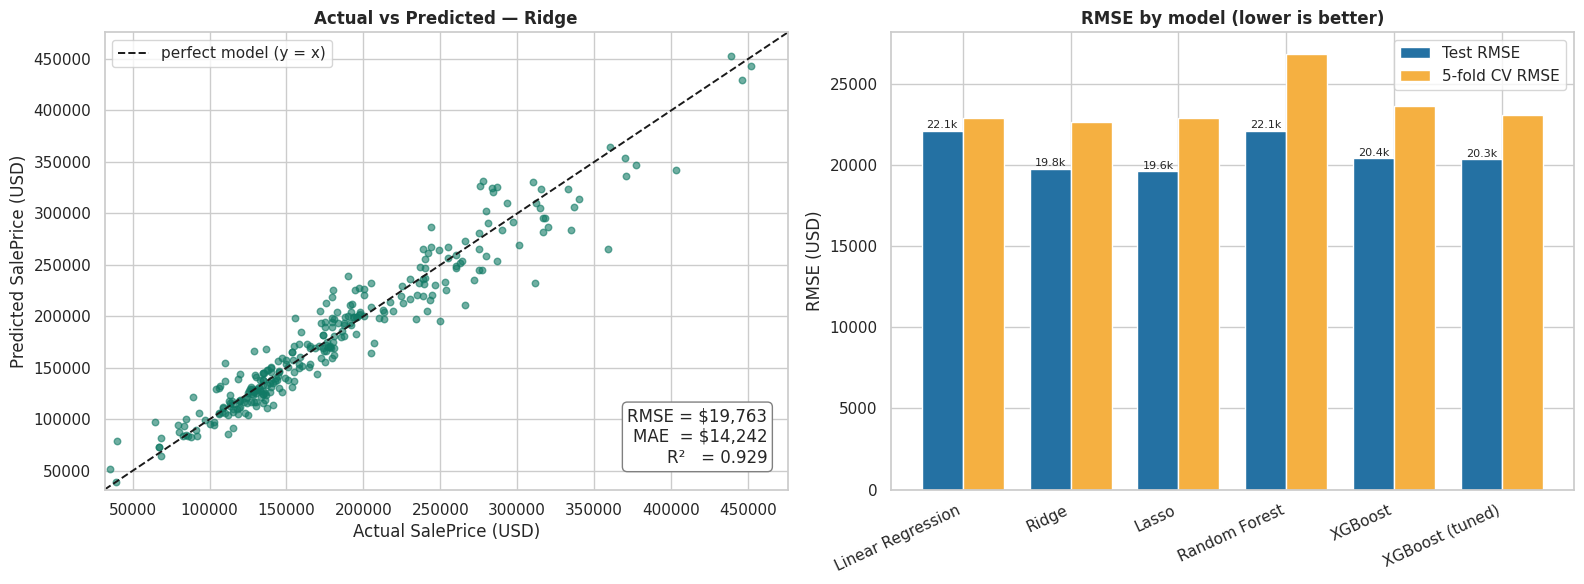

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
plot_avp(best_name, ax=ax[0], color="#117a65")
w = .38; x = np.arange(len(order))
ax[1].bar(x - w/2, comp["RMSE (USD)"], w, label="Test RMSE", color="#2471a3")
ax[1].bar(x + w/2, comp["5-Fold CV RMSE (USD)"], w, label="5-fold CV RMSE", color="#f5b041")
ax[1].set_xticks(x); ax[1].set_xticklabels(order, rotation=25, ha="right"); ax[1].set_ylabel("RMSE (USD)"); ax[1].legend()
ax[1].set_title("RMSE by model (lower is better)")
for i, v in enumerate(comp["RMSE (USD)"]): ax[1].text(i - w/2, v + 150, f"{v/1000:.1f}k", ha="center", fontsize=8)
plt.tight_layout(); savefig("13_model_comparison"); plt.show()

**Best model: Ridge Regression.** It has the **lowest 5-fold CV RMSE ($22,655)** and the lowest test log-RMSE (0.1130), with a hold-out RMSE of $19,763 (R² = 0.929, MAE $14,242) — within 0.7 % of Lasso, the best on that single column. The gaps among Ridge, Lasso and tuned XGBoost are inside one CV standard deviation, so the decisive factors are **interpretability and production suitability**: Ridge is a linear model whose coefficients can be explained to agents and buyers, it trains in a fraction of a second (the tuned XGBoost search took ≈ 40 s), it is deterministic, and its pickle is ~21 KB. Tree ensembles did **not** beat the regularised linear model here because, after the log-target, quality ordinal encoding and target encoding, the signal is largely additive, and ~1,200 training rows are too few for boosting to exploit deep interactions (Random Forest was worst at $22,113 test / $26,839 CV RMSE).

> **Real-world context.** A start-up like NoBroker cares about RMSE in absolute terms. Relative error is the currency-free way to judge it: the table's *MAPE* and *Within ±10 %* columns say how often an automated estimate would land within a typical negotiation band of the true price.

---
## Step 7 — Residual Analysis & Model Interpretation
### 7.1 Residual plots (best model, test set)
Residual = *actual − predicted* on the **log1p scale** (where the model is fitted, so a residual of 0.1 ≈ a 10 % error); the USD view is shown in the 4th panel.

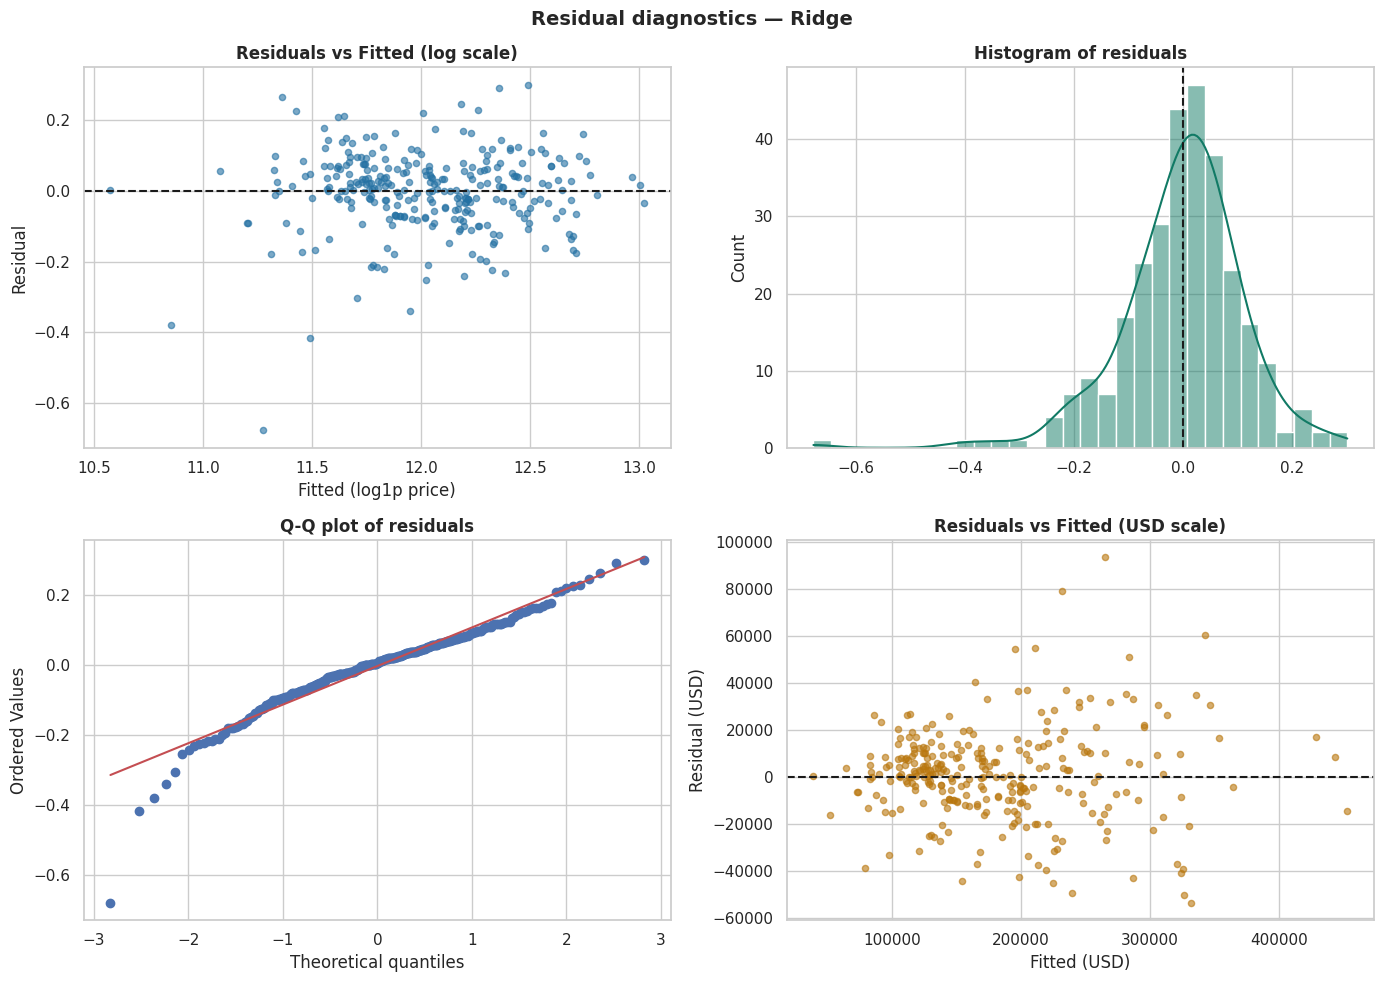

,mean,std,skew,exkurt,shapiro_p,n_gt3,n_gt2
residual statistics,-0.0017,0.1132,-1.0832,4.7819,0.0,3.0,13.0


Spearman(|resid|, fitted) = 0.031 (p = 0.592)  → heteroscedasticity check


,actual,predicted,error %,Neighborhood,OverallQual,SaleCondition
30,40000.0,78844.8,97.1,IDOTRR,4,Normal
1432,64500.0,97843.4,51.7,OldTown,4,Normal
916,35311.0,51611.2,46.2,IDOTRR,2,Abnorml
728,110000.0,154348.8,40.3,NAmes,5,Abnorml
479,89471.0,121234.6,35.5,OldTown,4,Alloca
666,129000.0,166119.6,28.8,NAmes,6,Abnorml


In [28]:
best_model = clone(base_models[best_name])
best_pipe = Pipeline([("prep", make_preprocessor()), ("model", best_model)]).fit(X_train, y_train)
p_log = best_pipe.predict(X_test); resid = y_test.values - p_log
assert np.allclose(np.expm1(p_log), preds[best_name], rtol=1e-6), "best_pipe should reproduce the table predictions"

fig, ax = plt.subplots(2, 2, figsize=(14, 10))
ax[0, 0].scatter(p_log, resid, s=20, alpha=.6, color="#2471a3"); ax[0, 0].axhline(0, color="k", ls="--")
ax[0, 0].set_xlabel("Fitted (log1p price)"); ax[0, 0].set_ylabel("Residual"); ax[0, 0].set_title("Residuals vs Fitted (log scale)")
sns.histplot(resid, kde=True, bins=30, color="#117a65", ax=ax[0, 1]); ax[0, 1].axvline(0, color="k", ls="--"); ax[0, 1].set_title("Histogram of residuals")
stats.probplot(resid, dist="norm", plot=ax[1, 0]); ax[1, 0].set_title("Q-Q plot of residuals")
res_usd = y_test_usd - preds[best_name]
ax[1, 1].scatter(preds[best_name], res_usd, s=20, alpha=.6, color="#b9770e"); ax[1, 1].axhline(0, color="k", ls="--")
ax[1, 1].set_xlabel("Fitted (USD)"); ax[1, 1].set_ylabel("Residual (USD)"); ax[1, 1].set_title("Residuals vs Fitted (USD scale)")
plt.suptitle(f"Residual diagnostics — {best_name}", fontsize=14, fontweight="bold"); plt.tight_layout(); savefig("14_residual_analysis"); plt.show()

sd = resid.std(ddof=1)
rs = dict(mean=resid.mean(), std=sd, skew=stats.skew(resid), exkurt=stats.kurtosis(resid), shapiro_p=stats.shapiro(resid).pvalue,
          n_gt3=int((np.abs(resid) > 3 * sd).sum()), n_gt2=int((np.abs(resid) > 2 * sd).sum()))
display(pd.Series(rs).round(4).to_frame("residual statistics").T)
# is the spread of residuals related to the price level?
rho, p_rho = stats.spearmanr(p_log, np.abs(resid)); print(f"Spearman(|resid|, fitted) = {rho:.3f} (p = {p_rho:.3f})  → heteroscedasticity check")
worst = pd.DataFrame({"actual": y_test_usd, "predicted": preds[best_name], "error %": (preds[best_name] / y_test_usd - 1) * 100,
                      "Neighborhood": X_test["Neighborhood"].values, "OverallQual": X_test["OverallQual"].values,
                      "SaleCondition": X_test_raw["SaleCondition"].values}, index=X_test.index)
worst = worst.reindex(worst["error %"].abs().sort_values(ascending=False).index).head(6)
display(worst.round(1))

**Reading the diagnostics (Ridge, test set).**
- **Residuals vs fitted:** a structureless horizontal band around 0 — no curvature (the linear form is adequate after the log transform) and no funnel (Spearman between |residual| and fitted value ≈ 0.03, p = 0.59), so the constant-variance assumption holds on the log scale. In USD the spread widens with price, which is expected: the model makes roughly constant *percentage* errors (typical error ≈ 11 %, MAPE 8.3 %).
- **Histogram:** bell-shaped and centred at ≈ 0 (mean −0.002, SD 0.113), but with a longer **left** tail (skewness −1.08).
- **Q-Q plot:** points follow the line in the middle but peel away at the lower end — **heavy left tail** (excess kurtosis 4.8, Shapiro p ≈ 2×10⁻⁹, 3 residuals beyond 3σ, 13 beyond 2σ). Residuals are therefore *not* strictly normal, so prediction intervals should be built from empirical quantiles rather than ±1.96σ.
- **Who is mis-priced?** The six largest errors are all **over-predictions** (+29 % to +97 %): four are low-quality homes (`OverallQual` 2–4) in IDOTRR / OldTown (e.g. actual $40,000 vs predicted $78,845) and three are `Abnorml` sales (foreclosure / family-type deals) whose discounts are invisible in the physical features. Practical rule: route low-quality-grade or abnormal-sale listings to a human appraiser.

### 7.2 Business interpretation — what drives the price?

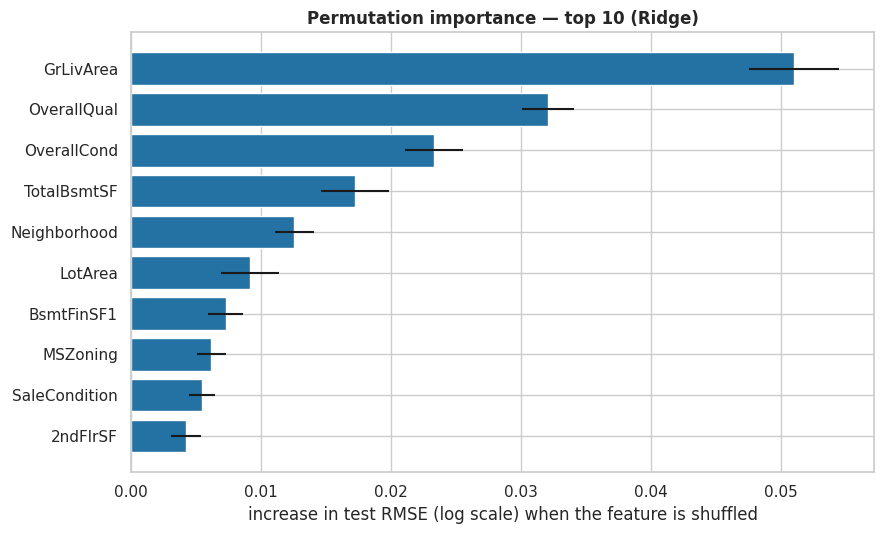

,feature,RMSE increase,std
44,GrLivArea,0.0510,0.0034
15,OverallQual,0.0321,0.0020
16,OverallCond,0.0233,0.0023
36,TotalBsmtSF,0.0173,0.0026
10,Neighborhood,0.0126,0.0015


,mean change %,median change %,mean change $
scenario,,,
+1 OverallQual point (capped at 10),4.46,4.50,7977.66
OverallQual → 10 (Excellent),18.54,19.23,29099.95
OverallQual → 5 (Average),-4.86,-4.30,-12276.01
+500 sq ft of living area,12.32,11.70,20235.50
house 20 years older,-2.07,-2.07,-3736.61
+1 garage bay,1.60,1.60,2891.73
KitchenQual → Excellent,3.23,2.23,5102.04
+1 OverallCond point (capped at 9),4.23,4.26,7633.75
+500 sq ft of basement,7.09,7.03,12597.54


Same house, OverallQual 10 vs 5: +24.6 %   |   same house in NridgHt vs MeadowV: +14.4 %


In [29]:
# Model-agnostic importance: permute each cleaned feature on the TEST set and measure the RMSE (log scale) increase
pi = permutation_importance(best_pipe, X_test, y_test, scoring="neg_root_mean_squared_error", n_repeats=20, random_state=RANDOM_STATE, n_jobs=1)
pi_df = pd.DataFrame({"feature": X_test.columns, "RMSE increase": pi.importances_mean, "std": pi.importances_std}).sort_values("RMSE increase", ascending=False)
top10 = pi_df.head(10)
plt.figure(figsize=(9, 5.5)); plt.barh(top10.feature[::-1], top10["RMSE increase"][::-1], xerr=top10["std"][::-1], color="#2471a3")
plt.xlabel("increase in test RMSE (log scale) when the feature is shuffled"); plt.title(f"Permutation importance — top 10 ({best_name})")
plt.tight_layout(); savefig("15_permutation_importance"); plt.show()
display(top10.head(5).round(4))

# What-if analysis on the SAME houses: change one thing, keep everything else fixed, compare predicted prices
def whatif(mod, label):
    Xm = X_test.copy(); mod(Xm)
    ratio = np.expm1(best_pipe.predict(Xm)) / np.expm1(best_pipe.predict(X_test)) - 1
    return {"scenario": label, "mean change %": ratio.mean() * 100, "median change %": np.median(ratio) * 100,
            "mean change $": (np.expm1(best_pipe.predict(Xm)) - np.expm1(best_pipe.predict(X_test))).mean()}
def add_area(Xm, d=500):
    for c in ["GrLivArea", "TotalSF", "1stFlrSF"]: Xm[c] = Xm[c] + d
def older(Xm, yrs=20): Xm["HouseAge"] = Xm["HouseAge"] + yrs; Xm["YearBuilt"] = Xm["YearBuilt"] - yrs
sc = [whatif(lambda X: X.__setitem__("OverallQual", (X.OverallQual + 1).clip(upper=10)), "+1 OverallQual point (capped at 10)"),
      whatif(lambda X: X.__setitem__("OverallQual", 10), "OverallQual → 10 (Excellent)"),
      whatif(lambda X: X.__setitem__("OverallQual", 5), "OverallQual → 5 (Average)"),
      whatif(add_area, "+500 sq ft of living area"),
      whatif(older, "house 20 years older"),
      whatif(lambda X: X.__setitem__("GarageCars", X.GarageCars + 1), "+1 garage bay"),
      whatif(lambda X: X.__setitem__("KitchenQual", 5), "KitchenQual → Excellent"),
      whatif(lambda X: X.__setitem__("OverallCond", (X.OverallCond + 1).clip(upper=9)), "+1 OverallCond point (capped at 9)"),
      whatif(lambda X: (X.__setitem__("TotalBsmtSF", X.TotalBsmtSF + 500), X.__setitem__("TotalSF", X.TotalSF + 500)), "+500 sq ft of basement"),
      whatif(lambda X: X.__setitem__("Neighborhood", order_med.index[0]), f"moved to priciest neighbourhood ({order_med.index[0]})"),
      whatif(lambda X: X.__setitem__("Neighborhood", order_med.index[-1]), f"moved to cheapest neighbourhood ({order_med.index[-1]})")]
sc_df = pd.DataFrame(sc).set_index("scenario"); display(sc_df.round(2))

# direct head-to-head comparisons on the same houses
def pred_usd(mod):
    Xm = X_test.copy(); mod(Xm); return np.expm1(best_pipe.predict(Xm))
q10v5 = (pred_usd(lambda X: X.__setitem__("OverallQual", 10)) / pred_usd(lambda X: X.__setitem__("OverallQual", 5)) - 1).mean() * 100
nb_swing = (pred_usd(lambda X: X.__setitem__("Neighborhood", order_med.index[0])) / pred_usd(lambda X: X.__setitem__("Neighborhood", order_med.index[-1])) - 1).mean() * 100
print(f"Same house, OverallQual 10 vs 5: {q10v5:+.1f} %   |   same house in {order_med.index[0]} vs {order_med.index[-1]}: {nb_swing:+.1f} %")

In [30]:
top5 = pi_df.head(5)["feature"].tolist()
assert top5 == ["GrLivArea", "OverallQual", "OverallCond", "TotalBsmtSF", "Neighborhood"], top5      # text below is written for these five
g = lambda k, col="mean change %": sc_df.loc[k, col]
display(Markdown(f'''
**Top 5 drivers (permutation importance) and what they mean in plain English** *(effects are "same house, one change" what-if predictions from the final model)*

1. **`GrLivArea` (above-ground living area) – the single strongest signal.** Adding 500 sq ft of living space raises the predicted price by about **{g("+500 sq ft of living area"):.0f} %** (≈ ${g("+500 sq ft of living area", "mean change $"):,.0f}). `TotalSF` carries the same information, which is why permutation importance gives the credit to `GrLivArea`.
2. **`OverallQual` (build quality, 1–10).** Each extra quality point is worth about **{g("+1 OverallQual point (capped at 10)"):.1f} %**; the same house rated Excellent (10) instead of Average (5) is predicted **{q10v5:.0f} % higher**. The raw median gap between 10-rated and 5-rated homes is far bigger because high-quality homes are also larger, newer and in better areas — the model separates those effects.
3. **`OverallCond` (condition).** A better-kept house sells for more, but the effect is modest: one extra condition point ≈ **{g("+1 OverallCond point (capped at 9)"):.1f} %**. Quality of construction matters more than present condition.
4. **`TotalBsmtSF` (basement area).** A 500 sq ft larger basement adds about **{g("+500 sq ft of basement"):.0f} %** (≈ ${g("+500 sq ft of basement", "mean change $"):,.0f}) — usable below-ground space is valued, though less than living area.
5. **`Neighborhood` – location, location, location.** The identical house is predicted **{nb_swing:.0f} % more** in the priciest neighbourhood ({order_med.index[0]}) than in the cheapest ({order_med.index[-1]}).

*Takeaway for a real-estate professional:* price is driven by **how big, how well built and where** — renovation ROI is highest for adding usable area and improving build quality, while age alone matters little once those are accounted for (20 years older ≈ {g("house 20 years older"):.0f} %).
'''))


**Top 5 drivers (permutation importance) and what they mean in plain English** *(effects are "same house, one change" what-if predictions from the final model)*

1. **`GrLivArea` (above-ground living area) – the single strongest signal.** Adding 500 sq ft of living space raises the predicted price by about **12 %** (≈ $20,235). `TotalSF` carries the same information, which is why permutation importance gives the credit to `GrLivArea`.
2. **`OverallQual` (build quality, 1–10).** Each extra quality point is worth about **4.5 %**; the same house rated Excellent (10) instead of Average (5) is predicted **25 % higher**. The raw median gap between 10-rated and 5-rated homes is far bigger because high-quality homes are also larger, newer and in better areas — the model separates those effects.
3. **`OverallCond` (condition).** A better-kept house sells for more, but the effect is modest: one extra condition point ≈ **4.2 %**. Quality of construction matters more than present condition.
4. **`TotalBsmtSF` (basement area).** A 500 sq ft larger basement adds about **7 %** (≈ $12,598) — usable below-ground space is valued, though less than living area.
5. **`Neighborhood` – location, location, location.** The identical house is predicted **14 % more** in the priciest neighbourhood (NridgHt) than in the cheapest (MeadowV).

*Takeaway for a real-estate professional:* price is driven by **how big, how well built and where** — renovation ROI is highest for adding usable area and improving build quality, while age alone matters little once those are accounted for (20 years older ≈ -2 %).


**(Optional bonus) SHAP on the XGBoost model.** SHAP assigns every feature a signed contribution to each individual prediction. We explain the *tuned XGBoost* (the exam asks for XGBoost explicitly), whether or not it is the overall winner.

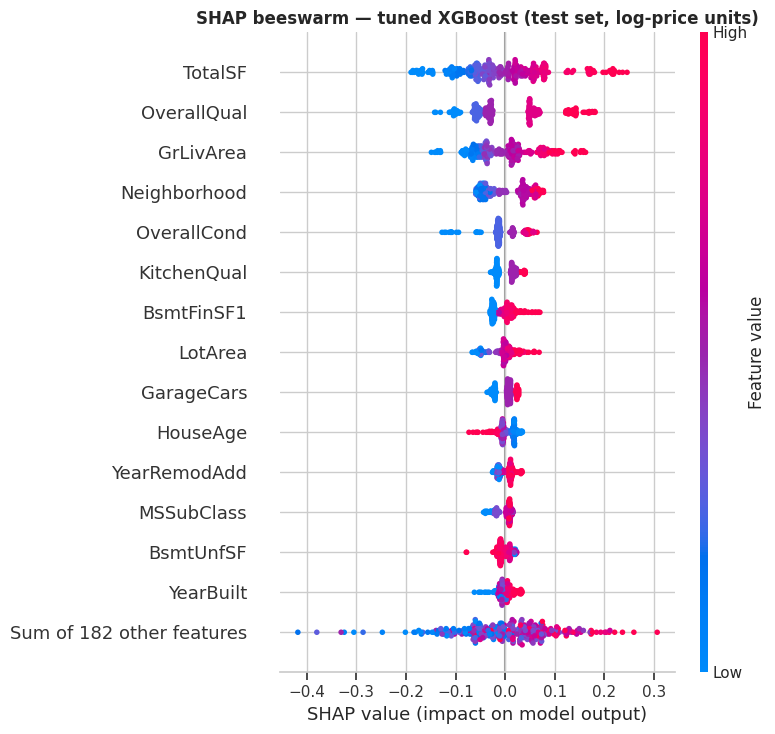

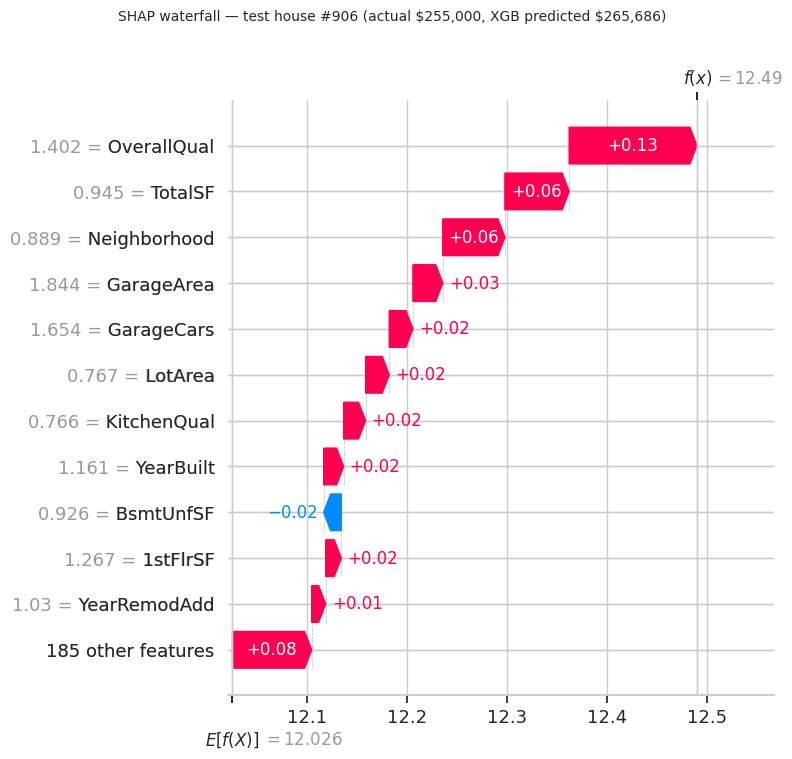

,TotalSF,OverallQual,GrLivArea,Neighborhood,OverallCond,KitchenQual,BsmtFinSF1,LotArea
mean |SHAP|,0.0727,0.0697,0.0506,0.043,0.025,0.0186,0.0181,0.0159


In [31]:
import shap
xgb_pipe = tuned_pipe                                    # tuned XGBoost pipeline (prep already fitted on train)
Xs_test = xgb_pipe.named_steps["prep"].transform(X_test)
explainer = shap.TreeExplainer(xgb_pipe.named_steps["model"])
sv = explainer(Xs_test); sv.feature_names = list(feat_names)
plt.figure(); shap.plots.beeswarm(sv, max_display=15, show=False); plt.title("SHAP beeswarm — tuned XGBoost (test set, log-price units)")
plt.tight_layout(); savefig("16_shap_beeswarm"); plt.show()
i = int(np.argsort(np.abs(preds["XGBoost (tuned)"] - y_test_usd))[len(y_test_usd) // 2])   # a typical (median-error) house
plt.figure(); shap.plots.waterfall(sv[i], max_display=12, show=False)
plt.gcf().suptitle(f"SHAP waterfall — test house #{X_test.index[i]} (actual ${y_test_usd[i]:,.0f}, XGB predicted ${preds['XGBoost (tuned)'][i]:,.0f})".replace("$", r"\$"), fontsize=10, y=1.01)
plt.tight_layout(); savefig("17_shap_waterfall"); plt.show()
shap_top = pd.Series(np.abs(sv.values).mean(0), index=feat_names).sort_values(ascending=False).head(8)
display(shap_top.rename("mean |SHAP|").to_frame().round(4).T)

---
## Step 8 — Pipeline, Deployment & GitHub Submission
### 8.1 Save the final pipeline
One `sklearn.pipeline.Pipeline` = **`HouseCleaner`** (raw rows → cleaned + engineered features) → **`ColumnTransformer`** (impute / log / scale / encode) → **best model** (wrapped in `LogTargetRegressor` so `predict()` returns **USD** directly). It is trained on the raw training rows and accepts raw rows in the original `train.csv` format.

In [32]:
final_pipe = Pipeline([("cleaner", HouseCleaner()),
                       ("prep", make_preprocessor()),
                       ("model", LogTargetRegressor(clone(base_models[best_name])))])
final_pipe.fit(X_train_raw, y_train)                       # raw rows in, log1p target in
p_final = final_pipe.predict(X_test_raw)                   # USD out
assert np.allclose(p_final, preds[best_name], rtol=1e-6), "final pipeline must reproduce the evaluated predictions"
print(f"Final pipeline [{best_name}] on RAW test rows → RMSE ${mean_squared_error(y_test_usd, p_final) ** .5:,.0f} | "
      f"MAE ${mean_absolute_error(y_test_usd, p_final):,.0f} | R² {r2_score(y_test_usd, p_final):.4f}   (identical to the table ✔)")
print("Steps:", [n for n, _ in final_pipe.steps])
joblib.dump(final_pipe, "../models/house_price_model.pkl")
print(f"Saved → models/house_price_model.pkl ({os.path.getsize('../models/house_price_model.pkl') / 1024:.0f} KB)")

Final pipeline [Ridge] on RAW test rows → RMSE $19,763 | MAE $14,242 | R² 0.9293   (identical to the table ✔)
Steps: ['cleaner', 'prep', 'model']
Saved → models/house_price_model.pkl (21 KB)


In [33]:
# Test it: load the pickle IN A FRESH PYTHON PROCESS and predict 5 sample rows (raw format) → compare with actual prices
sample = X_test_raw.sample(5, random_state=RANDOM_STATE)
sample.to_csv("_sample_rows.csv", na_rep="NA")
import subprocess
code_str = ("import joblib, pandas as pd, numpy as np; "
            "m = joblib.load('../models/house_price_model.pkl'); "
            "s = pd.read_csv('_sample_rows.csv', index_col=0, keep_default_na=False, na_values=['NA']); "
            "np.save('_sample_pred.npy', m.predict(s))")
r = subprocess.run([sys.executable, "-c", code_str], capture_output=True, text=True, env={**os.environ, "PYTHONPATH": "../src"}); assert r.returncode == 0, r.stderr
pred_sample = np.load("_sample_pred.npy")
actual_sample = np.expm1(y_test.loc[sample.index]).values
check_df = pd.DataFrame({"Neighborhood": sample.Neighborhood.values, "OverallQual": sample.OverallQual.values, "GrLivArea": sample.GrLivArea.values,
                         "Actual ($)": actual_sample, "Predicted ($)": pred_sample, "Error ($)": pred_sample - actual_sample,
                         "Error (%)": (pred_sample / actual_sample - 1) * 100}, index=sample.index)
display(check_df.style.format({"Actual ($)": "{:,.0f}", "Predicted ($)": "{:,.0f}", "Error ($)": "{:+,.0f}", "Error (%)": "{:+.1f}%"}))
print("Loaded pickle in a new process — predictions match in-memory model:", np.allclose(pred_sample, final_pipe.predict(sample)))
for f in ["_sample_rows.csv", "_sample_pred.npy"]: os.remove(f)

,Neighborhood,OverallQual,GrLivArea,Actual ($),Predicted ($),Error ($),Error (%)
416,Sawyer,6,1400,"149,500","153,319","+3,819",+2.6%
1095,CollgCr,6,1314,"176,432","175,342","-1,090",-0.6%
758,Somerst,7,1501,"179,400","159,495","-19,905",-11.1%
239,Edwards,6,1487,"113,000","123,945","+10,945",+9.7%
883,SWISU,4,2230,"118,500","139,078","+20,578",+17.4%


Loaded pickle in a new process — predictions match in-memory model: True


### 8.2 Persist metrics for the README / summary report

In [34]:
top5_features = pi_df.head(5)["feature"].tolist()
metrics = {"best_model": best_name, "best_params_tuned_xgb": {k.replace("model__", ""): (float(v) if isinstance(v, float) else int(v)) for k, v in search.best_params_.items()},
           "n_train": int(len(X_train)), "n_test": int(len(X_test)), "n_features_processed": int(len(feat_names)),
           "removed_outlier_rows": int(out_mask.sum()), "dropped_sparse_cols": sparse_cols,
           "ridge_alpha": float(ridge.alpha_), "lasso_alpha": float(lasso.alpha_), "lasso_zeroed": n_zero, "lasso_total": int(len(lasso.coef_)),
           "cv_best_log_mean": float(cv_mean), "cv_best_log_std": float(cv_std),
           "comparison": json.loads(comp.drop(columns=["CV RMSE ± std (USD)"]).to_json(orient="index")),
           "cv_usd_std": {m: cv_res[m]["CV RMSE USD std"] for m in order},
           "top5_permutation": top5_features, "whatif": json.loads(sc_df.to_json(orient="index")),
           "residual_stats": rs, "skew_raw": float(sk_raw), "skew_log": float(sk_log),
           "median_price": float(np.median(y_test_usd)), "q10v5": float(q10v5), "nb_swing": float(nb_swing),
           "top_neigh": order_med.index[0], "bottom_neigh": order_med.index[-1]}
json.dump(metrics, open("../results/metrics.json", "w"), indent=2, default=float)
comp.drop(columns=["CV RMSE ± std (USD)"]).round(4).to_csv("../results/model_comparison.csv")
print("Saved results/metrics.json and results/model_comparison.csv")
print("Top-5 features by permutation importance:", top5_features)

Saved results/metrics.json and results/model_comparison.csv
Top-5 features by permutation importance: ['GrLivArea', 'OverallQual', 'OverallCond', 'TotalBsmtSF', 'Neighborhood']


### 8.3 GitHub submission
Repository **`house-price-regression-supervised-learning`** containing: `HousePrice_SupervisedLearning.ipynb`, `house_price_model.pkl`, `summary_report.md`, `requirements.txt`, `README.md` (+ the helper module `house_preprocessing.py`, which the pickle needs, and the `images/` used by the README).

---
**✅ Submission checklist** — notebook runs top-to-bottom without errors · all plots visible · model-comparison table present (Step 6) · metrics reported in original USD scale · model pickle saved & tested · summary report written.